# EDA 2. PaySim – синтетические операции мобильных денег

Проект: обнаружение мошеннических транзакций в условиях сильного дисбаланса классов.

Данные: [Kaggle – ealaxi/paysim1](https://www.kaggle.com/datasets/ealaxi/paysim1), статья Lopez-Rojas, Elmir, Axelsson, "PaySim: A financial mobile money simulator for fraud detection" (2016). Это примерно 6.4 млн операций, которые сгенерировал агентный симулятор. Симулятор настраивали по месячным логам реального сервиса мобильных денег в одной из африканских стран.

Признаки:
- `step` – номер часа симуляции (1 шаг = 1 час, всего около 30 дней)
- `type` – тип операции: CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER
- `amount` – сумма
- `nameOrig`, `nameDest` – id отправителя и получателя (C – клиент, M – мерчант)
- `oldbalanceOrg`, `newbalanceOrig` – баланс отправителя до и после операции
- `oldbalanceDest`, `newbalanceDest` – баланс получателя до и после
- `isFraud` – таргет
- `isFlaggedFraud` – флаг от уже существующего правила, по описанию это перевод больше 200 000

Нам этот датасет нужен, потому что тут, в отличие от ULB, признаки понятные: есть тип операции, балансы и целый месяц по времени. На нем удобно смотреть утечки, артефакты генерации и то, как меняется доля мошенничества во времени.

Файл `paysim.csv` кладем в папку `data/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.ensemble import IsolationForest
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
PAL = {0: '#4C72B0', 1: '#D1495B'}
RS = 42

## 1. Загрузка и общий обзор

In [2]:
df = pd.read_csv('data/paysim.csv', dtype={'type': 'category'})
print(df.shape)
print('Память, ГБ:', round(df.memory_usage(deep=True).sum() / 1e9, 2))
df.head()

(6362620, 11)
Память, ГБ: 1.17


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


In [3]:
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Non-Null Count    Dtype   
---  ------          --------------    -----   
 0   step            6362620 non-null  int64   
 1   type            6362620 non-null  category
 2   amount          6362620 non-null  float64 
 3   nameOrig        6362620 non-null  str     
 4   oldbalanceOrg   6362620 non-null  float64 
 5   newbalanceOrig  6362620 non-null  float64 
 6   nameDest        6362620 non-null  str     
 7   oldbalanceDest  6362620 non-null  float64 
 8   newbalanceDest  6362620 non-null  float64 
 9   isFraud         6362620 non-null  int64   
 10  isFlaggedFraud  6362620 non-null  int64   
dtypes: category(1), float64(5), int64(3), str(2)
memory usage: 491.5 MB


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
step,"6,362,620.0000",NaN,NaN,NaN,243.3972,142.3320,1.0000,156.0000,239.0000,335.0000,743.0000
type,6362620,5,CASH_OUT,2237500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,"6,362,620.0000",NaN,NaN,NaN,"179,861.9035","603,858.2315",0.0000,"13,389.5700","74,871.9400","208,721.4775","92,445,516.6400"
nameOrig,6362620,6353307,C2098525306,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceOrg,"6,362,620.0000",NaN,NaN,NaN,"833,883.1041","2,888,242.6730",0.0000,0.0000,"14,208.0000","107,315.1750","59,585,040.3700"
newbalanceOrig,"6,362,620.0000",NaN,NaN,NaN,"855,113.6686","2,924,048.5030",0.0000,0.0000,0.0000,"144,258.4100","49,585,040.3700"
nameDest,6362620,2722362,C1286084959,113,NaN,NaN,NaN,NaN,NaN,NaN,NaN
oldbalanceDest,"6,362,620.0000",NaN,NaN,NaN,"1,100,701.6665","3,399,180.1130",0.0000,0.0000,"132,705.6650","943,036.7075","356,015,889.3500"
newbalanceDest,"6,362,620.0000",NaN,NaN,NaN,"1,224,996.3982","3,674,128.9421",0.0000,0.0000,"214,661.4400","1,111,909.2500","356,179,278.9200"
isFraud,"6,362,620.0000",NaN,NaN,NaN,0.0013,0.0359,0.0000,0.0000,0.0000,0.0000,1.0000


Что видно из describe:
- 6 362 620 операций и 11 столбцов, из них 3 строковых (`type`, `nameOrig`, `nameDest`)
- `step` от 1 до 743, это примерно 31 день
- `amount` от 0 до 92 млн при медиане около 75 тыс., хвост очень тяжелый
- у балансов медиана и даже квартили часто равны 0, с нулевыми балансами надо будет разобраться отдельно
- `nameOrig` почти уникальный (6.35 млн уникальных на 6.36 млн строк), то есть истории отправителя в датасете по сути нет. `nameDest` повторяется чаще, 2.7 млн уникальных
- чаще всего встречается CASH_OUT, потом PAYMENT и CASH_IN

## 2. Целевая переменная и степень дисбаланса

In [5]:
cnt = df['isFraud'].value_counts().sort_index()
print(pd.DataFrame({'count': cnt, 'share': cnt / len(df)}))
print('Соотношение классов 1 :', round(cnt[0] / cnt[1]))
print('PR-AUC случайного классификатора:', round(cnt[1] / len(df), 5))

           count  share
isFraud                
0        6354407 0.9987
1           8213 0.0013
Соотношение классов 1 : 774
PR-AUC случайного классификатора: 0.00129


In [6]:
by_type = df.groupby('type', observed=True)['isFraud'].agg(n='size', n_fraud='sum', fraud_rate='mean')
by_type['share_of_all_fraud'] = by_type['n_fraud'] / by_type['n_fraud'].sum()
by_type

,n,n_fraud,fraud_rate,share_of_all_fraud
type,,,,
CASH_IN,1399284,0,0.0000,0.0000
CASH_OUT,2237500,4116,0.0018,0.5012
DEBIT,41432,0,0.0000,0.0000
PAYMENT,2151495,0,0.0000,0.0000
TRANSFER,532909,4097,0.0077,0.4988


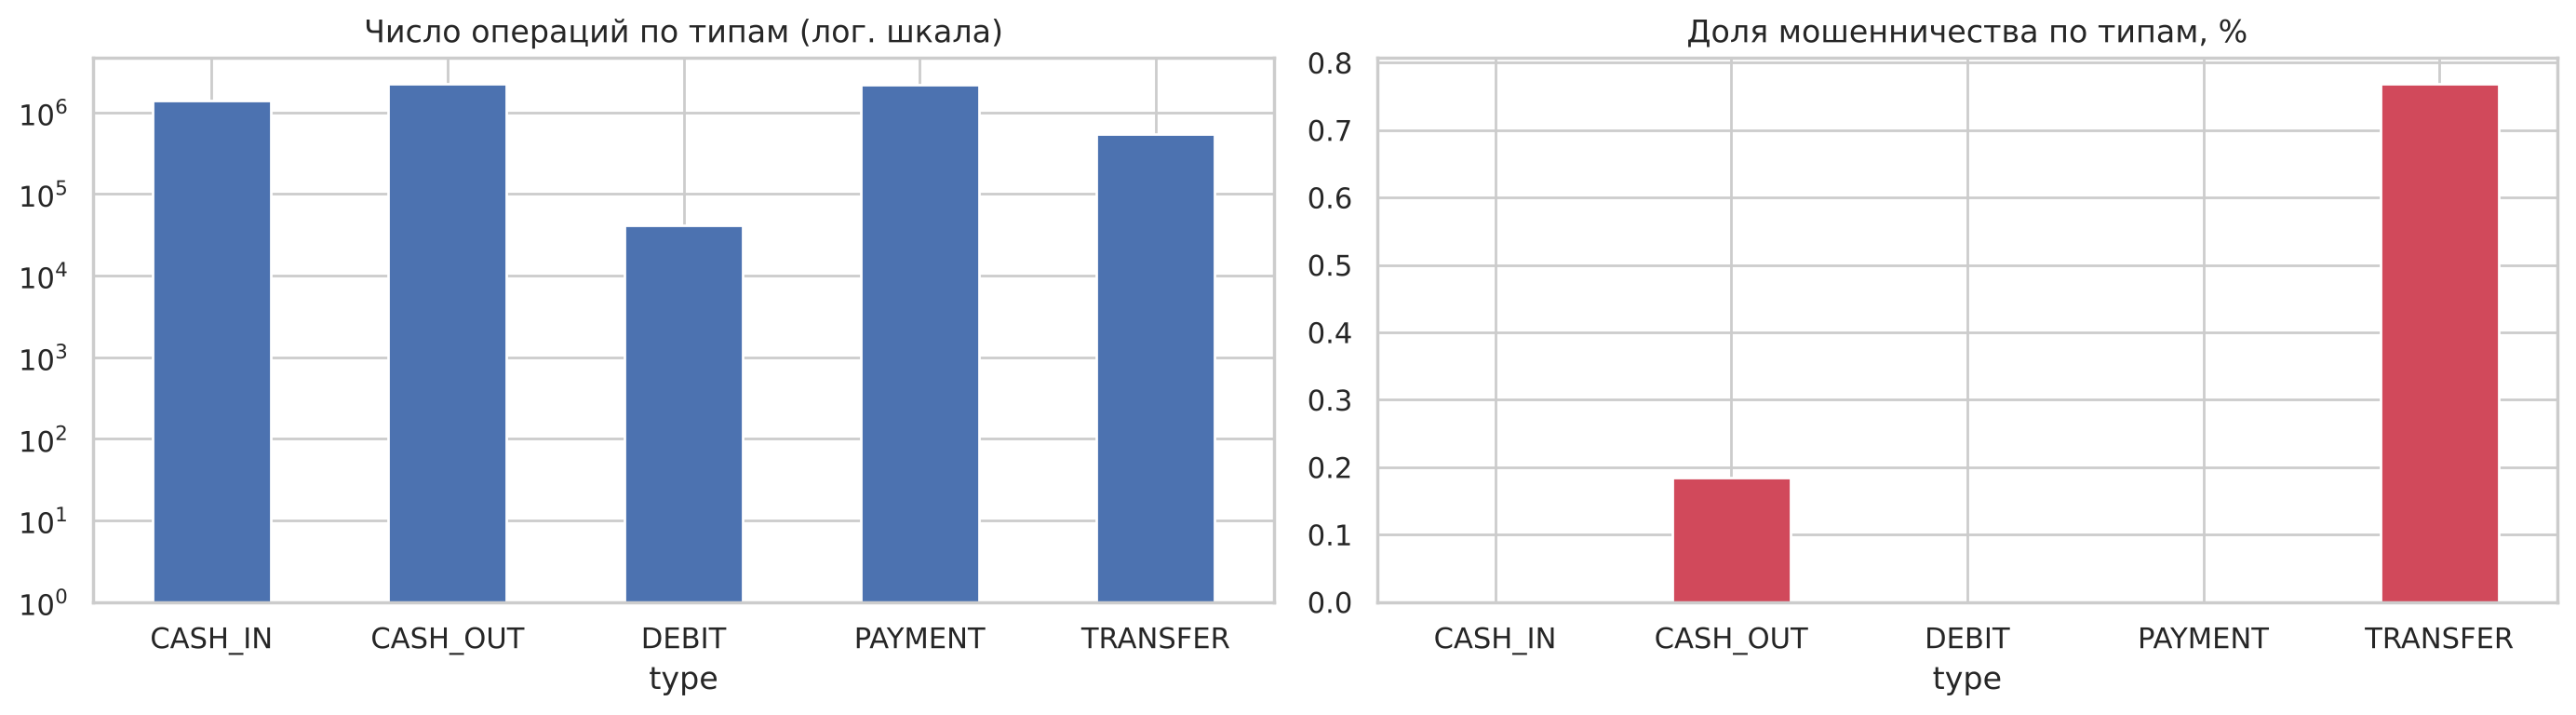

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_type['n'].plot.bar(ax=axes[0], color=PAL[0], log=True)
axes[0].set_title('Число операций по типам (лог. шкала)')
axes[0].tick_params(axis='x', rotation=0)
(by_type['fraud_rate'] * 100).plot.bar(ax=axes[1], color=PAL[1])
axes[1].set_title('Доля мошенничества по типам, %')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

- Мошенничества 0.13%, то есть 1 к 774, дисбаланс даже сильнее, чем в ULB.
- Мошенничество есть только в TRANSFER и CASH_OUT и делится между ними почти поровну. Так задан сценарий в симуляторе: злоумышленник получает доступ к счету, переводит деньги на свой счет (TRANSFER) и снимает их (CASH_OUT).
- Внутри TRANSFER и CASH_OUT мошенничества около 0.3%. Для модели имеет смысл оставить только эти два типа, в остальных 3.6 млн операций нет ни одного положительного примера. В реальной системе это был бы просто фильтр по типу операции.

In [8]:
pd.crosstab(df['isFlaggedFraud'], df['isFraud'], margins=True)

isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


Правило `isFlaggedFraud` сработало всего 16 раз (и все 16 действительно мошенничество), то есть recall у него 0.2%. Ниже проверим, работает ли оно так, как написано в описании.

## 3. Пропущенные значения

In [9]:
na = df.isna().sum().to_frame('n_missing')
na['share'] = na['n_missing'] / len(df)
print('Доля пропущенных ячеек:', na['n_missing'].sum() / df.size)
na.T

Доля пропущенных ячеек: 0.0


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
n_missing,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
share,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


Явных пропусков нет. Но в описании датасета сказано, что для мерчантов (получатели с `M`) балансов нет. Значит, нули в балансах могут быть закодированными пропусками, а не настоящими нулями. Проверим три гипотезы:

1. У всех мерчантов-получателей балансы до и после равны 0, то есть это пропуск по построению.
2. У клиентов-получателей бывают операции, где баланс до и после равен 0, хотя сумма больше нуля. При нормальном учете так быть не может, значит, баланс просто неизвестен.
3. У отправителей бывает `oldbalanceOrg = 0` при положительной сумме. Отправить деньги с пустого счета нельзя, значит, здесь баланс тоже неизвестен.

In [10]:
df['dest_is_merchant'] = df['nameDest'].str.startswith('M')
df['orig_is_merchant'] = df['nameOrig'].str.startswith('M')
pos_amt = df['amount'] > 0
df['dest_bal_missing'] = df['oldbalanceDest'].eq(0) & df['newbalanceDest'].eq(0) & pos_amt
df['orig_bal_missing'] = df['oldbalanceOrg'].eq(0) & pos_amt

print('Получатель-мерчант, доля строк:', round(df['dest_is_merchant'].mean(), 4))
print('Отправитель-мерчант, строк:', df['orig_is_merchant'].sum())
print('Типы операций с мерчантом-получателем:', list(df.loc[df['dest_is_merchant'], 'type'].unique()))
print('Доля нулевых балансов получателя у мерчантов:', df.loc[df['dest_is_merchant'], 'dest_bal_missing'].mean())

Получатель-мерчант, доля строк: 0.3381
Отправитель-мерчант, строк: 0
Типы операций с мерчантом-получателем: ['PAYMENT']
Доля нулевых балансов получателя у мерчантов: 1.0


In [11]:
miss = []
for col in ['dest_bal_missing', 'orig_bal_missing']:
    for t in ['TRANSFER', 'CASH_OUT', 'CASH_IN', 'DEBIT', 'PAYMENT']:
        sub = df[(df['type'] == t) & ~df['dest_is_merchant']] if col == 'dest_bal_missing' else df[df['type'] == t]
        if len(sub) == 0:
            continue
        miss.append({'pattern': col, 'type': t, 'share_all': sub[col].mean(),
                     'share_in_fraud': sub.loc[sub['isFraud'] == 1, col].mean() if sub['isFraud'].sum() else np.nan,
                     'share_in_legit': sub.loc[sub['isFraud'] == 0, col].mean()})
miss = pd.DataFrame(miss)
miss

,pattern,type,share_all,share_in_fraud,share_in_legit
0,dest_bal_missing,TRANSFER,0.0078,0.9929,0.0002
1,dest_bal_missing,CASH_OUT,0.0007,0.0005,0.0007
2,dest_bal_missing,CASH_IN,0.1143,NaN,0.1143
3,dest_bal_missing,DEBIT,0.0000,NaN,0.0000
4,orig_bal_missing,TRANSFER,0.5306,0.0010,0.5347
5,orig_bal_missing,CASH_OUT,0.4585,0.0051,0.4593
6,orig_bal_missing,CASH_IN,0.0096,NaN,0.0096
7,orig_bal_missing,DEBIT,0.1486,NaN,0.1486
8,orig_bal_missing,PAYMENT,0.3599,NaN,0.3599


In [12]:
tc = df['type'].isin(['TRANSFER', 'CASH_OUT'])
for col in ['dest_bal_missing', 'orig_bal_missing']:
    sub = df[tc & ~df['dest_is_merchant']]
    r = sub.groupby(col)['isFraud'].mean()
    print(col, 'доля мошенничества при False:', round(r[False], 5), 'при True:', round(r[True], 5))

dest_bal_missing доля мошенничества при False: 0.0015 при True: 0.70464


orig_bal_missing доля мошенничества при False: 0.0056 при True: 2e-05


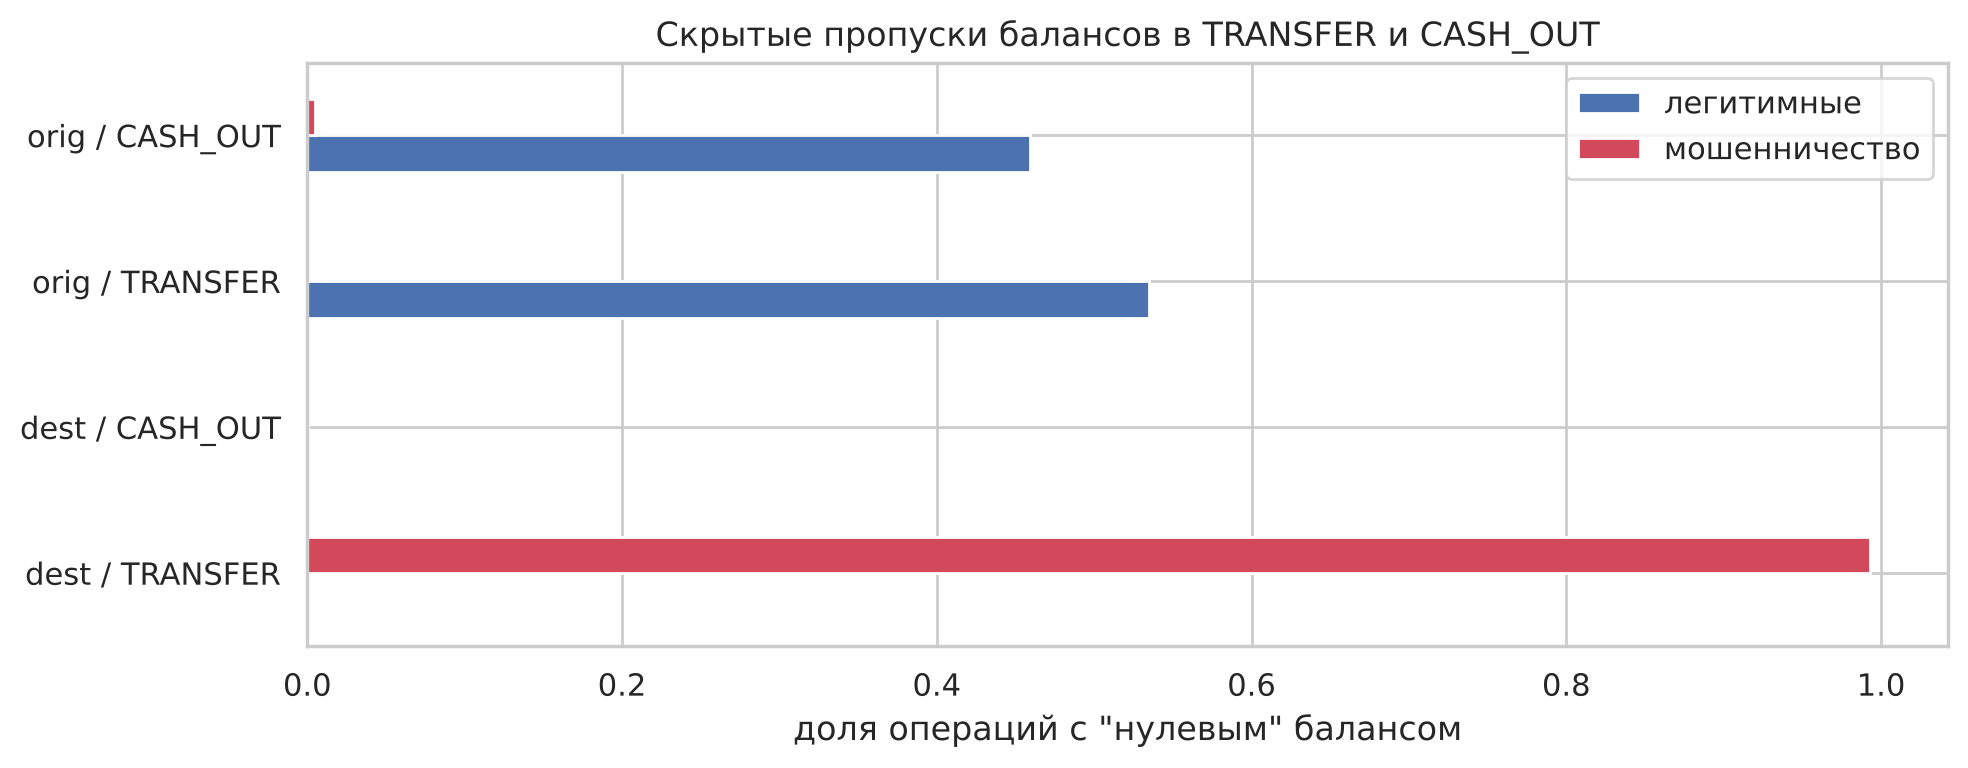

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
p = miss.set_index(['pattern', 'type'])[['share_in_legit', 'share_in_fraud']].dropna()
p.index = [f'{a.replace("_bal_missing", "")} / {b}' for a, b in p.index]
p.plot.barh(ax=ax, color=[PAL[0], PAL[1]])
ax.set_xlabel('доля операций с "нулевым" балансом')
ax.legend(['легитимные', 'мошенничество'])
ax.set_title('Скрытые пропуски балансов в TRANSFER и CASH_OUT')
plt.tight_layout()
plt.show()

Что получилось:
- Гипотеза 1 подтвердилась: все операции с мерчантом это PAYMENT, и у всех балансы получателя нули. Это 34% строк, пропуск по построению.
- Гипотеза 2: в нормальных TRANSFER нулевые балансы получателя почти не встречаются (0.02%), а в мошеннических TRANSFER они в 99% случаев. В CASH_OUT такого нет. Среди TRANSFER и CASH_OUT с "пропущенным" балансом получателя 70% это мошенничество. Похоже, что симулятор просто не обновляет баланс счета, на который переводит мошенник. Еще в CASH_IN баланс получателя "пропущен" у 11% нормальных операций.
- Гипотеза 3: нулевой баланс отправителя при положительной сумме есть примерно у половины нормальных TRANSFER и CASH_OUT, а у мошеннических почти нет (0.1–0.5%). Мошенник выводит именно те деньги, которые на счету есть.

То есть пропуски сильно зависят от таргета, это точно не MCAR. Если заполнить их нулями или медианой, мы эту информацию потеряем.

Как обрабатываем:
- у мерчантов балансы получателя заменяем на NaN. Они нам и не нужны, мерчанты бывают только в PAYMENT, а там мошенничества нет
- для TRANSFER и CASH_OUT добавляем индикаторы `dest_bal_missing` и `orig_bal_missing`, а сами нули заменяем на NaN. XGBoost умеет работать с NaN сам
- отдельно проверим, не являются ли эти индикаторы просто артефактом генератора (раздел 11)

## 4. Ошибочные значения

In [14]:
num_cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
checks = pd.Series({
    'isFraud вне {0, 1}': (~df['isFraud'].isin([0, 1])).sum(),
    'isFlaggedFraud вне {0, 1}': (~df['isFlaggedFraud'].isin([0, 1])).sum(),
    'отрицательные суммы или балансы': int((df[num_cols] < 0).sum().sum()),
    'amount = 0': (df['amount'] == 0).sum(),
    'step вне [1, 744]': (~df['step'].between(1, 744)).sum(),
    'полные дубликаты': df.duplicated().sum(),
    'повторяющиеся nameOrig': df['nameOrig'].duplicated().sum(),
})
checks.to_frame('n_rows')

,n_rows
"isFraud вне {0, 1}",0
"isFlaggedFraud вне {0, 1}",0
отрицательные суммы или балансы,0
amount = 0,16
"step вне [1, 744]",0
полные дубликаты,0
повторяющиеся nameOrig,9313


In [15]:
df.loc[df['amount'] == 0, ['step', 'type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'isFraud']]

,step,type,amount,oldbalanceOrg,newbalanceOrig,isFraud
2736447,212,CASH_OUT,0.0000,0.0000,0.0000,1
3247298,250,CASH_OUT,0.0000,0.0000,0.0000,1
3760289,279,CASH_OUT,0.0000,0.0000,0.0000,1
5563714,387,CASH_OUT,0.0000,0.0000,0.0000,1
5996408,425,CASH_OUT,0.0000,0.0000,0.0000,1
5996410,425,CASH_OUT,0.0000,0.0000,0.0000,1
6168500,554,CASH_OUT,0.0000,0.0000,0.0000,1
6205440,586,CASH_OUT,0.0000,0.0000,0.0000,1
6266414,617,CASH_OUT,0.0000,0.0000,0.0000,1
6281483,646,CASH_OUT,0.0000,0.0000,0.0000,1


16 операций с нулевой суммой, и все это мошеннические CASH_OUT с нулевым балансом отправителя. Перевод нуля это некорректная запись, похоже на попытку снять деньги с уже пустого счета. Строк мало, на распределения они не влияют, поэтому оставляем их, а в модели их можно выделить признаком `amount = 0`.

Самое важное, что тут можно проверить, это сходятся ли балансы: после операции баланс отправителя должен уменьшиться на сумму, а баланс получателя увеличиться на сумму.

In [16]:
df['err_orig'] = df['oldbalanceOrg'] - df['amount'] - df['newbalanceOrig']
df['err_dest'] = df['oldbalanceDest'] + df['amount'] - df['newbalanceDest']
bad = pd.DataFrame({
    'orig_inconsistent': df['err_orig'].abs() > 1,
    'dest_inconsistent': (df['err_dest'].abs() > 1) & ~df['dest_is_merchant'],
    'amount_gt_balance': df['amount'] > df['oldbalanceOrg'] + 1,
    'type': df['type'], 'isFraud': df['isFraud'],
})
bad.groupby(['type', 'isFraud'], observed=True)[['orig_inconsistent', 'dest_inconsistent', 'amount_gt_balance']].mean().round(3)

orig_inconsistent  dest_inconsistent  amount_gt_balance
type     isFraud                                                         
CASH_IN  0                   1.0000             1.0000             0.3410
CASH_OUT 0                   0.8870             0.0950             0.8870
         1                   0.0060             0.0340             0.0060
DEBIT    0                   0.2840             0.0830             0.2840
PAYMENT  0                   0.5120             0.0000             0.5120
TRANSFER 0                   0.9600             0.1020             0.9600
         1                   0.0050             0.9990             0.0010

Балансы не сходятся у большинства операций:
- в CASH_IN, PAYMENT, DEBIT и в нормальных TRANSFER и CASH_OUT сумма часто больше баланса отправителя, а новый баланс просто становится нулевым. Реальная система так бы не сделала
- у мошеннических операций наоборот: сумма почти всегда ровно равна балансу (счет опустошают полностью), и баланс отправителя сходится (не сходится только в 0.5% случаев), зато у мошеннических TRANSFER баланс получателя не меняется в 99.9% случаев

Это не опечатки, а систематические особенности генератора, и исправить их нельзя, настоящих балансов мы не знаем. Поэтому балансы не трогаем, но делаем из них признаки `err_orig`, `err_dest` и `empties_account = (amount == oldbalanceOrg)`, а в разделе 11 проверяем, не утечка ли это.

Теперь проверим правило `isFlaggedFraud`.

In [17]:
rule = (df['type'] == 'TRANSFER') & (df['amount'] > 200_000)
print('TRANSFER с суммой > 200 000:', rule.sum())
print('Из них с isFlaggedFraud = 1:', df.loc[rule, 'isFlaggedFraud'].sum())
df.loc[df['isFlaggedFraud'] == 1, ['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']].describe().round(0)

TRANSFER с суммой > 200 000: 409110
Из них с isFlaggedFraud = 1: 16


,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
count,16.0000,16.0000,16.0000,16.0000,16.0000
mean,"4,861,598.0000","7,817,869.0000","7,817,869.0000",0.0000,0.0000
std,"3,572,499.0000","6,972,669.0000","6,972,669.0000",0.0000,0.0000
min,"353,874.0000","353,874.0000","353,874.0000",0.0000,0.0000
25%,"2,242,749.0000","3,013,980.0000","3,013,980.0000",0.0000,0.0000
50%,"4,234,245.0000","4,923,043.0000","4,923,043.0000",0.0000,0.0000
75%,"7,883,451.0000","12,128,348.0000","12,128,348.0000",0.0000,0.0000
max,"10,000,000.0000","19,585,040.0000","19,585,040.0000",0.0000,0.0000


Правило из описания не выполняется: подходящих переводов около 409 тыс., а флаг стоит только у 16. Флаг стоит у TRANSFER на суммы от 0.35 до 10 млн, у всех баланс отправителя после операции не поменялся (то есть операцию заблокировали), а балансы получателя нулевые. Какая на самом деле логика у флага, по 16 примерам не понять.

В любом случае это выход уже существующей антифрод-системы, а не свойство самой операции, и информации в нем почти нет. Поэтому `isFlaggedFraud` из признаков убираем, но можно использовать его как самый простой бейзлайн для сравнения (recall 0.2%).

## 5. Выбросы

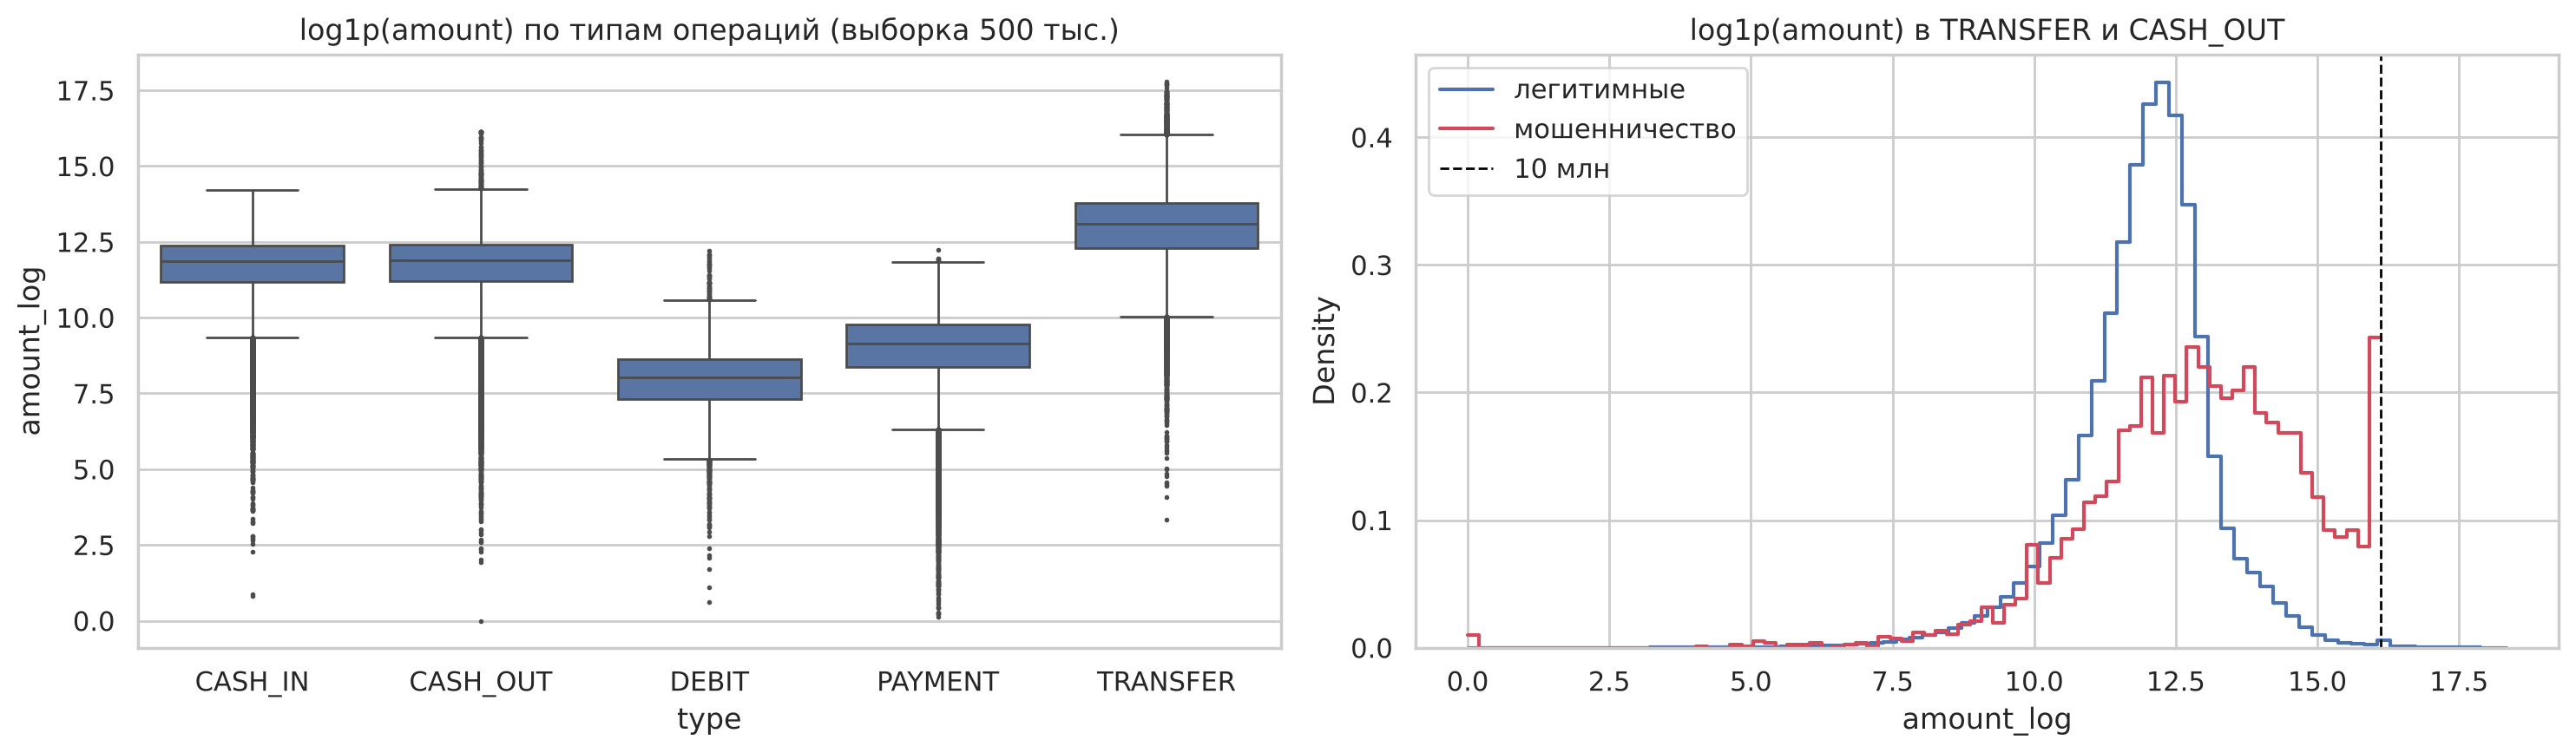

In [18]:
df['amount_log'] = np.log1p(df['amount'])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=df.sample(500_000, random_state=RS), x='type', y='amount_log', ax=axes[0], color=PAL[0], fliersize=1)
axes[0].set_title('log1p(amount) по типам операций (выборка 500 тыс.)')
tcd = df[tc]
for cls in [0, 1]:
    sns.histplot(tcd.loc[tcd['isFraud'] == cls, 'amount_log'], bins=80, stat='density', element='step', fill=False,
                 color=PAL[cls], ax=axes[1], label=['легитимные', 'мошенничество'][cls])
axes[1].axvline(np.log1p(10_000_000), color='black', ls='--', lw=1, label='10 млн')
axes[1].legend()
axes[1].set_title('log1p(amount) в TRANSFER и CASH_OUT')
plt.tight_layout()
plt.show()

In [19]:
def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

rows = []
for c in num_cols:
    m = iqr_mask(tcd[c])
    rows.append({'feature': c, 'outlier_share': m.mean(), 'fraud_rate_outliers': tcd.loc[m, 'isFraud'].mean(),
                 'fraud_rate_inliers': tcd.loc[~m, 'isFraud'].mean(), 'skew': tcd[c].skew(), 'max': tcd[c].max()})
pd.DataFrame(rows).set_index('feature')

,outlier_share,fraud_rate_outliers,fraud_rate_inliers,skew,max
feature,,,,,
amount,0.0805,0.0154,0.0019,21.9349,"92,445,516.6400"
oldbalanceOrg,0.1428,0.0171,0.0006,70.0118,"59,585,040.3700"
newbalanceOrig,0.0988,0.0006,0.0032,127.3196,"49,585,040.3700"
oldbalanceDest,0.1034,0.0009,0.0032,17.1602,"356,015,889.3500"
newbalanceDest,0.0997,0.0024,0.0030,16.4338,"356,179,278.9200"


In [20]:
f = df[df['isFraud'] == 1]
print('Максимальная мошенническая сумма:', f['amount'].max())
print('Мошеннических операций ровно на 10 млн:', (f['amount'] == 10_000_000).sum())
print('Легитимных операций больше 10 млн:', ((df['isFraud'] == 0) & (df['amount'] > 10_000_000)).sum())
big = f[f['oldbalanceOrg'] > 10_000_000]
print('Мошеннических операций со счетов, где больше 10 млн:', len(big))
print('Из них сумма ровно 10 млн:', (big['amount'] == 10_000_000).mean())

Максимальная мошенническая сумма: 10000000.0
Мошеннических операций ровно на 10 млн: 287
Легитимных операций больше 10 млн: 2443
Мошеннических операций со счетов, где больше 10 млн: 148
Из них сумма ровно 10 млн: 0.9797297297297297


- Суммы и балансы сильно скошены (асимметрия от 16 до 127), в каждом признаке 8–14% выбросов по IQR. После логарифма сумма выглядит почти нормально, так что `log1p` решает проблему масштаба.
- Среди выбросов по `amount` мошенничества в 8 раз больше, по `oldbalanceOrg` в 28 раз: мошенник выводит весь баланс, поэтому суммы у него крупнее. А среди выбросов по балансам после операции и балансам получателя мошенничества, наоборот, меньше.
- Еще один артефакт генератора: мошенническая сумма не бывает больше 10 млн. Если на счету больше, кража разбивается на несколько операций ровно по 10 млн (таких 287). Нормальные операции больше 10 млн есть, мошеннических нет. Модель легко может выучить правило "ровно 10 млн значит мошенничество", а в реальных данных такого не будет.

Выбросы не удаляем, это часть сигнала, а при 0.13% положительного класса терять примеры не хочется. Суммы и балансы берем через `log1p`, для LOF и One-Class SVM дополнительно `RobustScaler`. Признак "сумма ровно 10 млн" специально не делаем, чтобы модель не училась на артефакте.

## 6. Признаки по отдельности и связь с целевой переменной

Дальше смотрим только TRANSFER и CASH_OUT, потому что только там есть оба класса.

In [21]:
t = df[tc].copy()
t['type'] = t['type'].cat.remove_unused_categories()
t['hour'] = (t['step'] - 1) % 24
t['day'] = (t['step'] - 1) // 24
t['empties_account'] = (t['amount'] == t['oldbalanceOrg']).astype(int)
t['is_transfer'] = (t['type'] == 'TRANSFER').astype(int)
for c in ['oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']:
    t[c + '_log'] = np.log1p(t[c])
print(t.shape, 'доля мошенничества:', round(t['isFraud'].mean(), 5))

(2770409, 26) доля мошенничества: 0.00296


In [22]:
feats = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest',
         'err_orig', 'err_dest', 'empties_account', 'dest_bal_missing', 'orig_bal_missing', 'hour', 'step', 'is_transfer']
pos = t['isFraud'] == 1
rows = []
for c in feats:
    x = t[c].astype(float)
    auc = roc_auc_score(t['isFraud'], x)
    rows.append({'feature': c, 'roc_auc_1d': max(auc, 1 - auc), 'direction': '+' if auc >= 0.5 else '-',
                 'pr_auc_1d': average_precision_score(t['isFraud'], x if auc >= 0.5 else -x),
                 'median_legit': x[~pos].median(), 'median_fraud': x[pos].median()})
sep = pd.DataFrame(rows).set_index('feature').sort_values('roc_auc_1d', ascending=False)
sep

,roc_auc_1d,direction,pr_auc_1d,median_legit,median_fraud
feature,,,,,
empties_account,0.9891,+,0.9783,0.0000,1.0000
err_orig,0.9466,+,0.0353,"-144,200.8250",0.0000
oldbalanceOrg,0.9277,+,0.2902,283.0000,"438,983.4500"
oldbalanceDest,0.7859,-,0.0112,"558,272.9900",0.0000
err_dest,0.7486,+,0.2132,0.0000,"2,231.4600"
dest_bal_missing,0.7475,+,0.3507,0.0000,0.0000
orig_bal_missing,0.7353,-,0.0056,0.0000,0.0000
newbalanceDest,0.7267,-,0.1282,"829,902.9300","4,676.4200"
amount,0.6834,+,0.0194,"171,034.4600","441,423.4400"


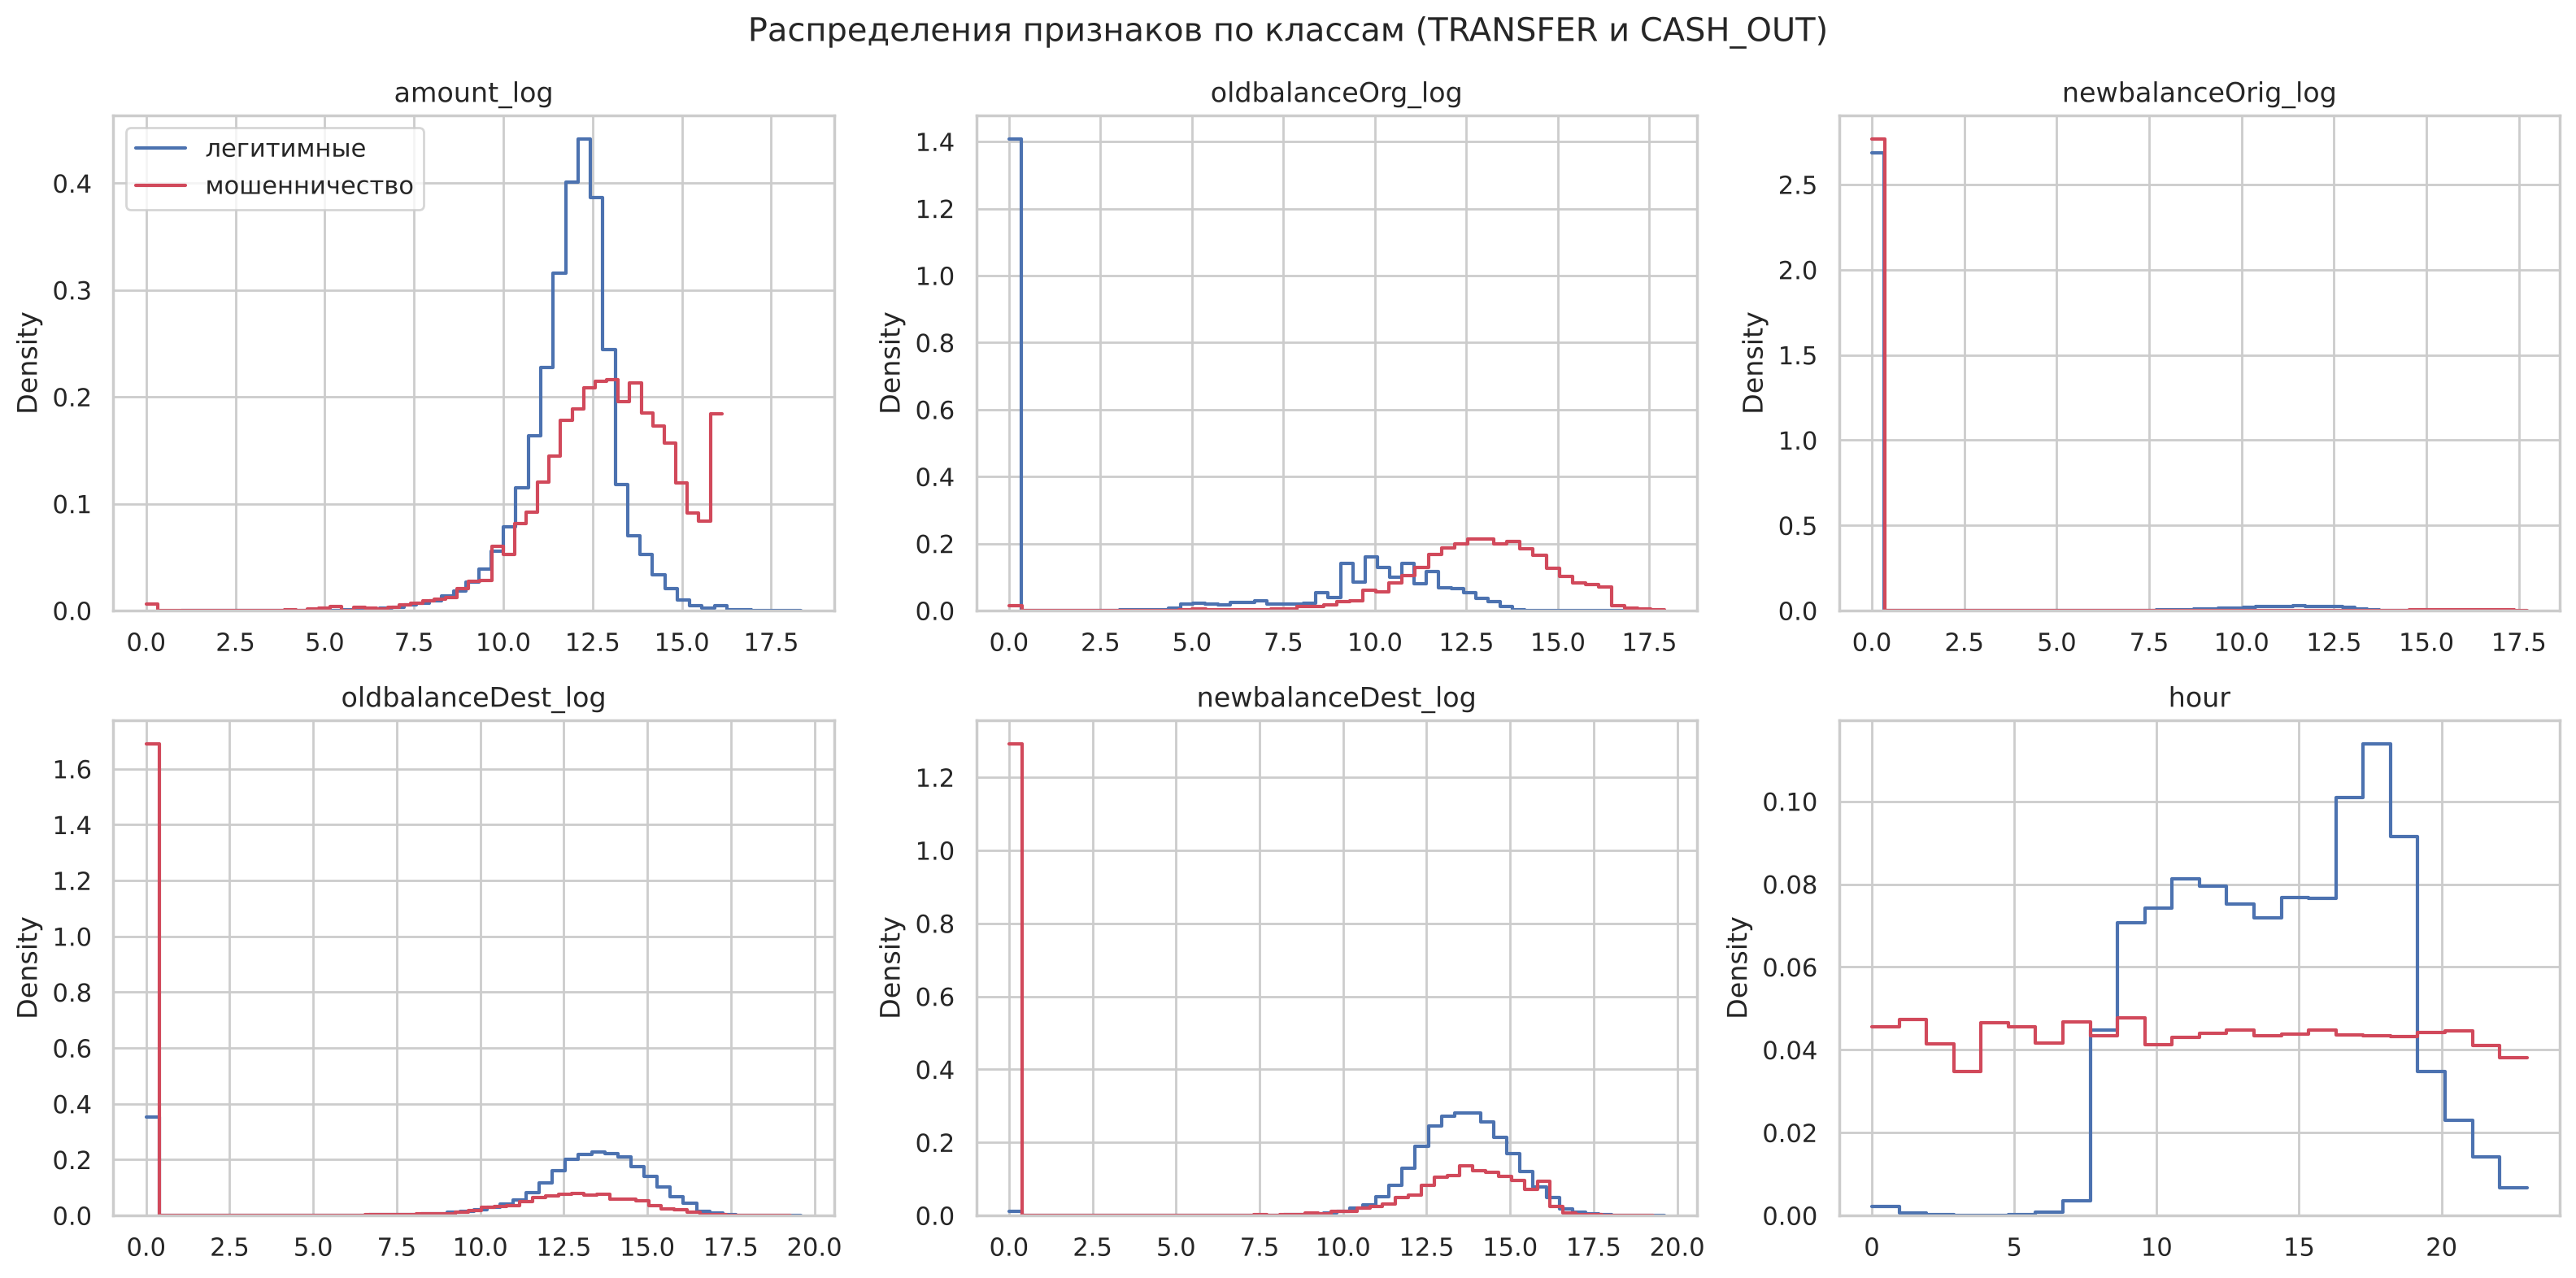

In [23]:
plot_cols = ['amount_log', 'oldbalanceOrg_log', 'newbalanceOrig_log', 'oldbalanceDest_log', 'newbalanceDest_log', 'hour']
smp = pd.concat([t[~pos].sample(200_000, random_state=RS), t[pos]])
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), plot_cols):
    for cls in [0, 1]:
        sns.histplot(smp.loc[smp['isFraud'] == cls, c], bins=50 if c != 'hour' else 24, stat='density',
                     element='step', fill=False, color=PAL[cls], ax=ax, label=['легитимные', 'мошенничество'][cls])
    ax.set_title(c)
    ax.set_xlabel('')
axes[0, 0].legend()
plt.suptitle('Распределения признаков по классам (TRANSFER и CASH_OUT)')
plt.tight_layout()
plt.show()

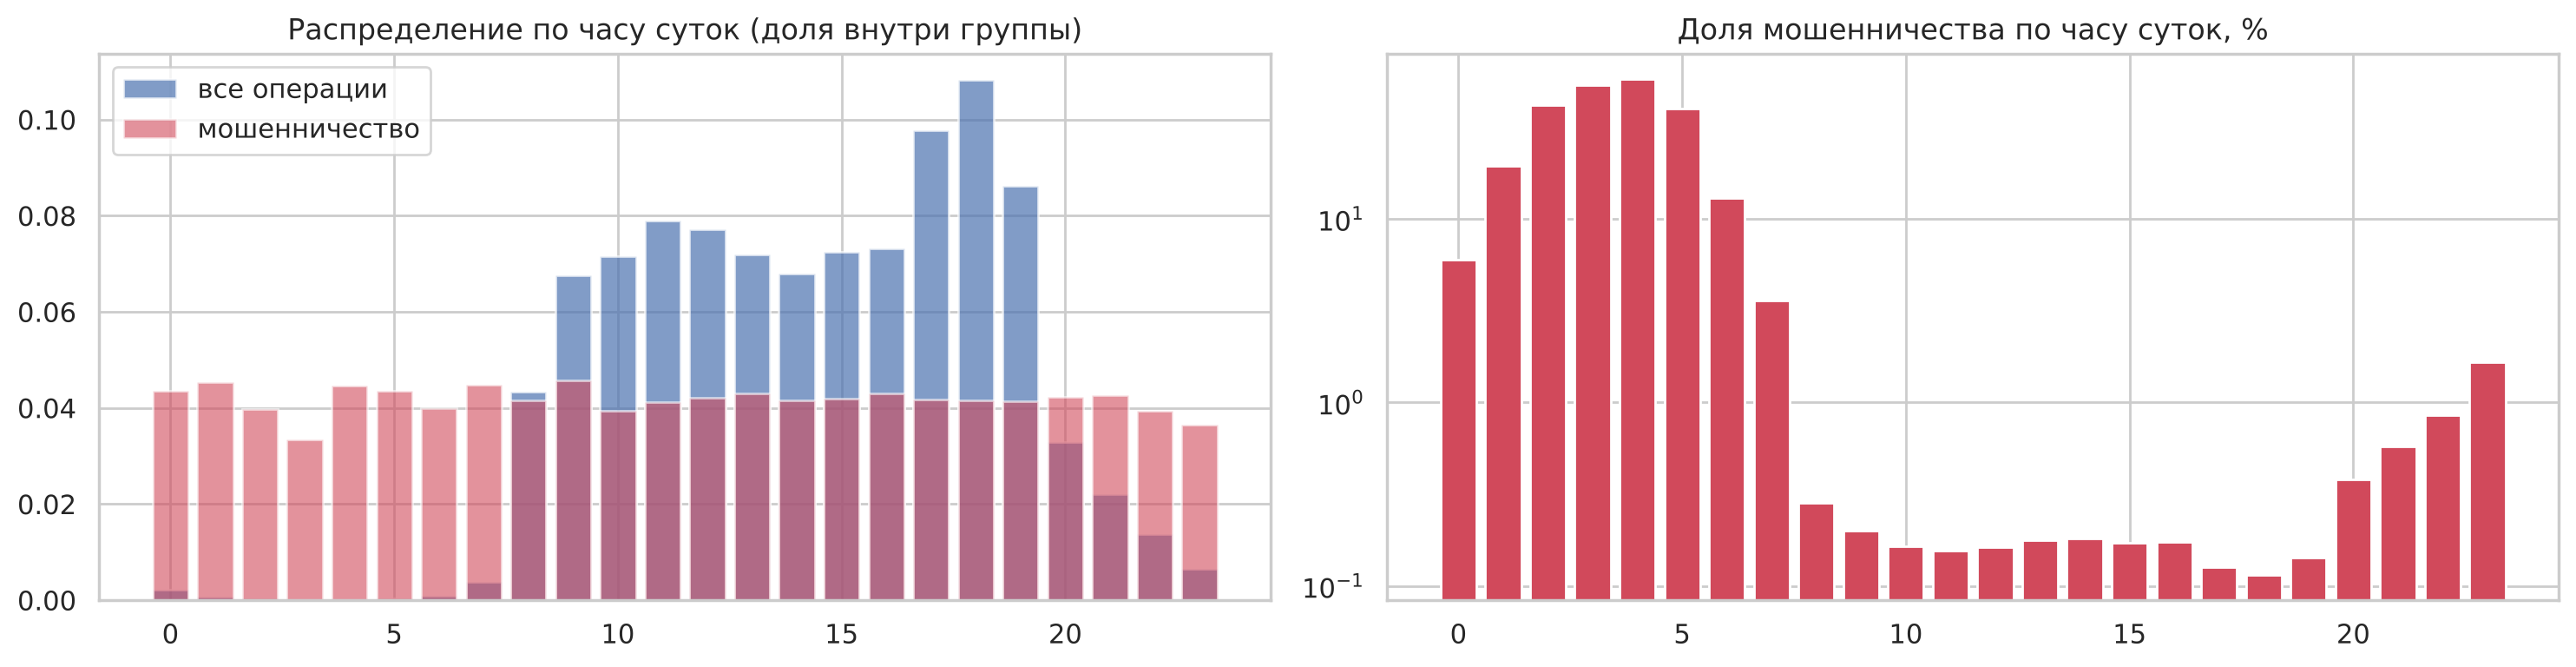

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
hr = t.groupby('hour').agg(n=('isFraud', 'size'), n_fraud=('isFraud', 'sum'))
axes[0].bar(hr.index, hr['n'] / hr['n'].sum(), color=PAL[0], alpha=0.7, label='все операции')
axes[0].bar(hr.index, hr['n_fraud'] / hr['n_fraud'].sum(), color=PAL[1], alpha=0.6, label='мошенничество')
axes[0].set_title('Распределение по часу суток (доля внутри группы)')
axes[0].legend()
axes[1].bar(hr.index, hr['n_fraud'] / hr['n'] * 100, color=PAL[1])
axes[1].set_title('Доля мошенничества по часу суток, %')
axes[1].set_yscale('log')
plt.tight_layout()
plt.show()

- Время суток. С 0 до 7 часов нормальных операций очень мало, а мошенничество идет почти равномерно весь день. Поэтому в 2–5 часов мошенничество составляет 40–58% операций, а днем всего 0.1–0.2%. Связь немонотонная, поэтому одномерный ROC-AUC у `hour` небольшой (0.63), но для деревьев это сильный и при этом правдоподобный признак.
- Сумма. У мошенничества суммы крупнее (медиана около 440 тыс. против 170 тыс.), но распределения сильно пересекаются, ROC-AUC около 0.68.
- Вывод всего баланса. Один бинарный признак `empties_account` (сумма ровно равна балансу) дает ROC-AUC 0.99 и PR-AUC 0.98. У нормальных операций такого совпадения не бывает вообще, а у мошеннических оно в 98% случаев. Это не поведение людей, а правило генератора, то есть почти прямая утечка таргета. Похожие `err_orig` и `oldbalanceOrg` дают ROC-AUC 0.93–0.95.

## 7. Корреляции

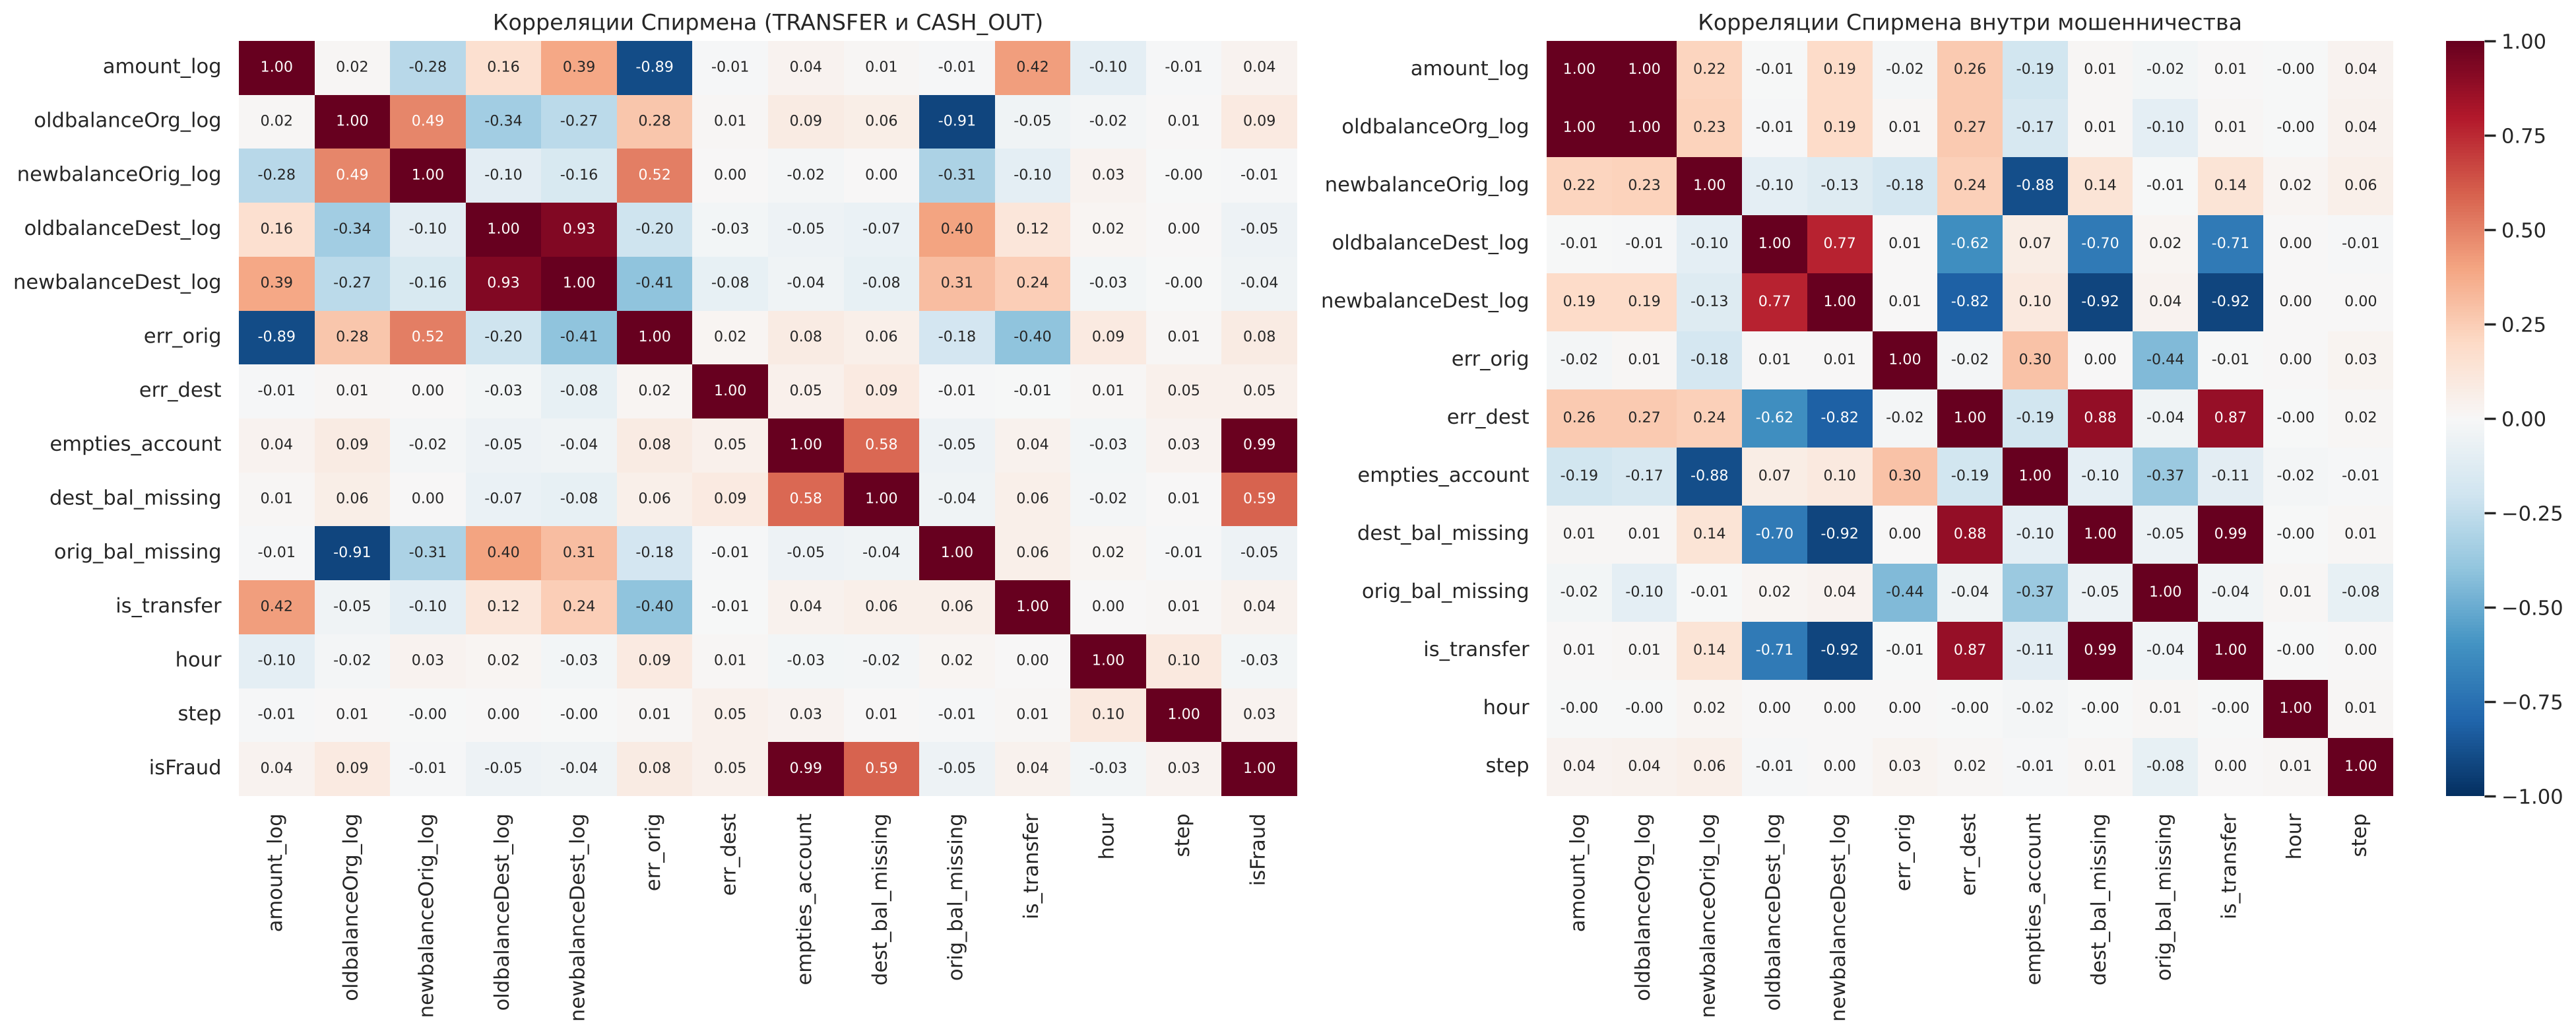

In [25]:
corr_cols = ['amount_log', 'oldbalanceOrg_log', 'newbalanceOrig_log', 'oldbalanceDest_log', 'newbalanceDest_log',
             'err_orig', 'err_dest', 'empties_account', 'dest_bal_missing', 'orig_bal_missing', 'is_transfer', 'hour', 'step', 'isFraud']
cs = t[corr_cols].sample(500_000, random_state=RS)
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
sns.heatmap(cs.corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False, annot_kws={'size': 8})
axes[0].set_title('Корреляции Спирмена (TRANSFER и CASH_OUT)')
sns.heatmap(t.loc[pos, corr_cols[:-1]].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[1], annot_kws={'size': 8})
axes[1].set_title('Корреляции Спирмена внутри мошенничества')
plt.tight_layout()
plt.show()

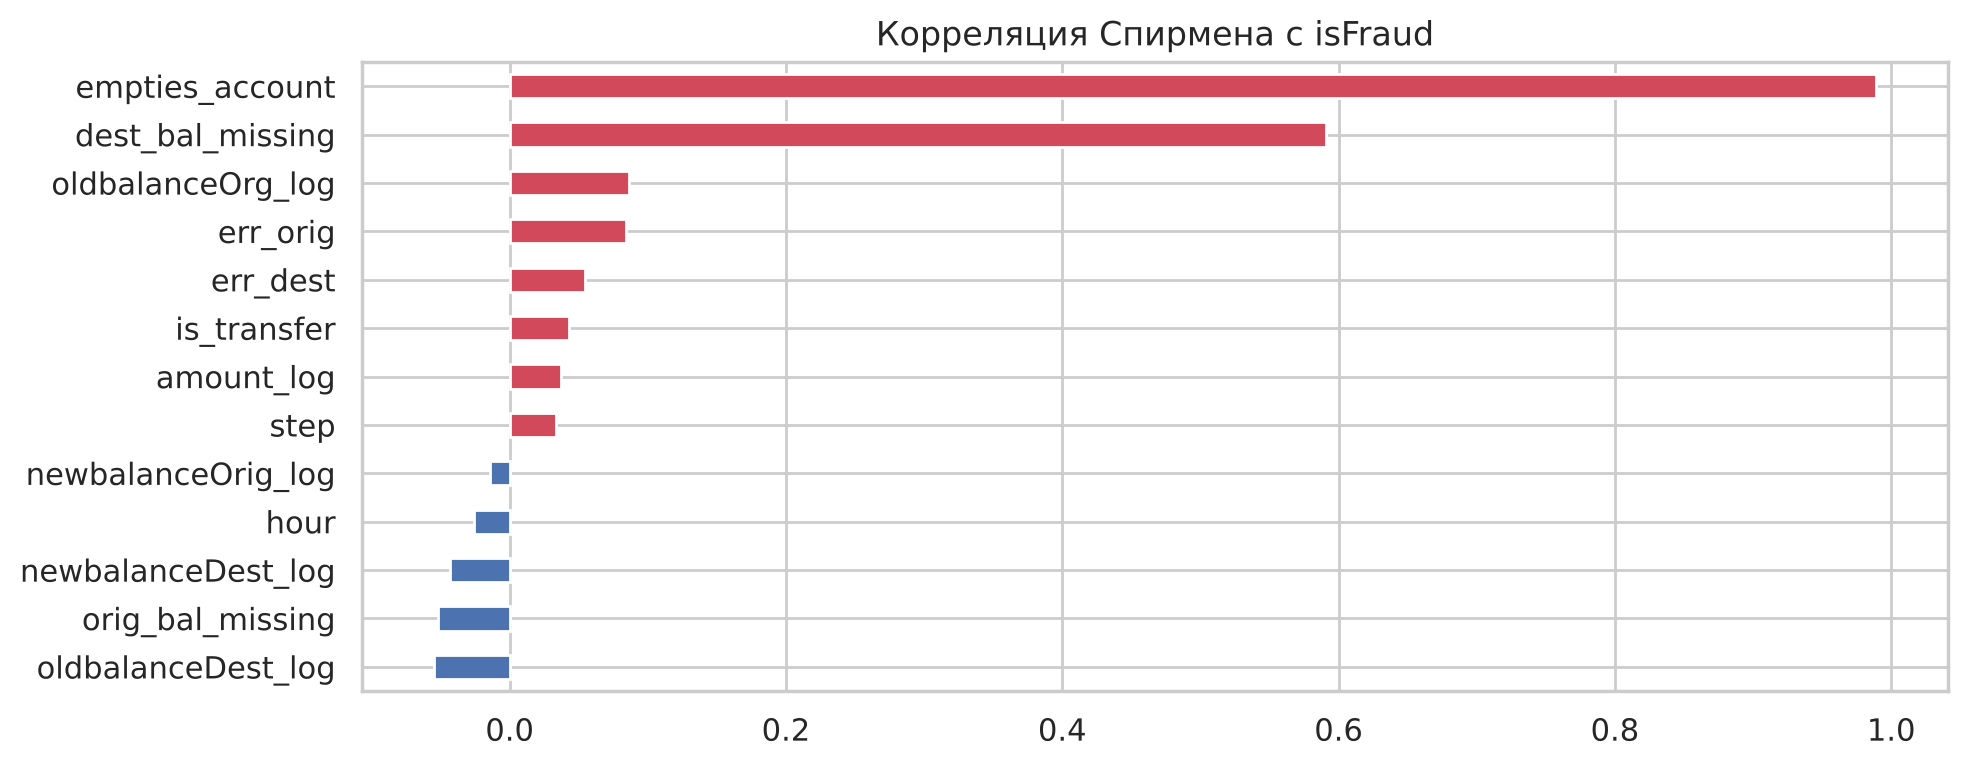

In [26]:
fig, ax = plt.subplots(figsize=(10, 4))
ct = cs.corr(method='spearman')['isFraud'].drop('isFraud').sort_values()
ct.plot.barh(ax=ax, color=np.where(ct > 0, PAL[1], PAL[0]))
ax.set_title('Корреляция Спирмена с isFraud')
plt.tight_layout()
plt.show()

- Балансы получателя до и после сильно коррелируют (0.93), балансы отправителя меньше (0.49). `err_orig` почти полностью определяется суммой (-0.89), а `orig_bal_missing` балансом отправителя (-0.91), так что часть признаков дублирует друг друга.
- Внутри мошенничества `amount` и `oldbalanceOrg` коррелируют почти идеально (около 0.99), это прямо следует из того, что мошенник выводит весь баланс.
- С таргетом заметно коррелируют только два признака: `empties_account` (около 0.99) и `dest_bal_missing` (около 0.6). У всех остальных, включая сумму и время, корреляция с таргетом меньше 0.1 по модулю, их связь с мошенничеством нелинейная и видна только во взаимодействиях. Когда один признак почти совпадает с таргетом, это обычно признак утечки.

## 8. Попарные распределения

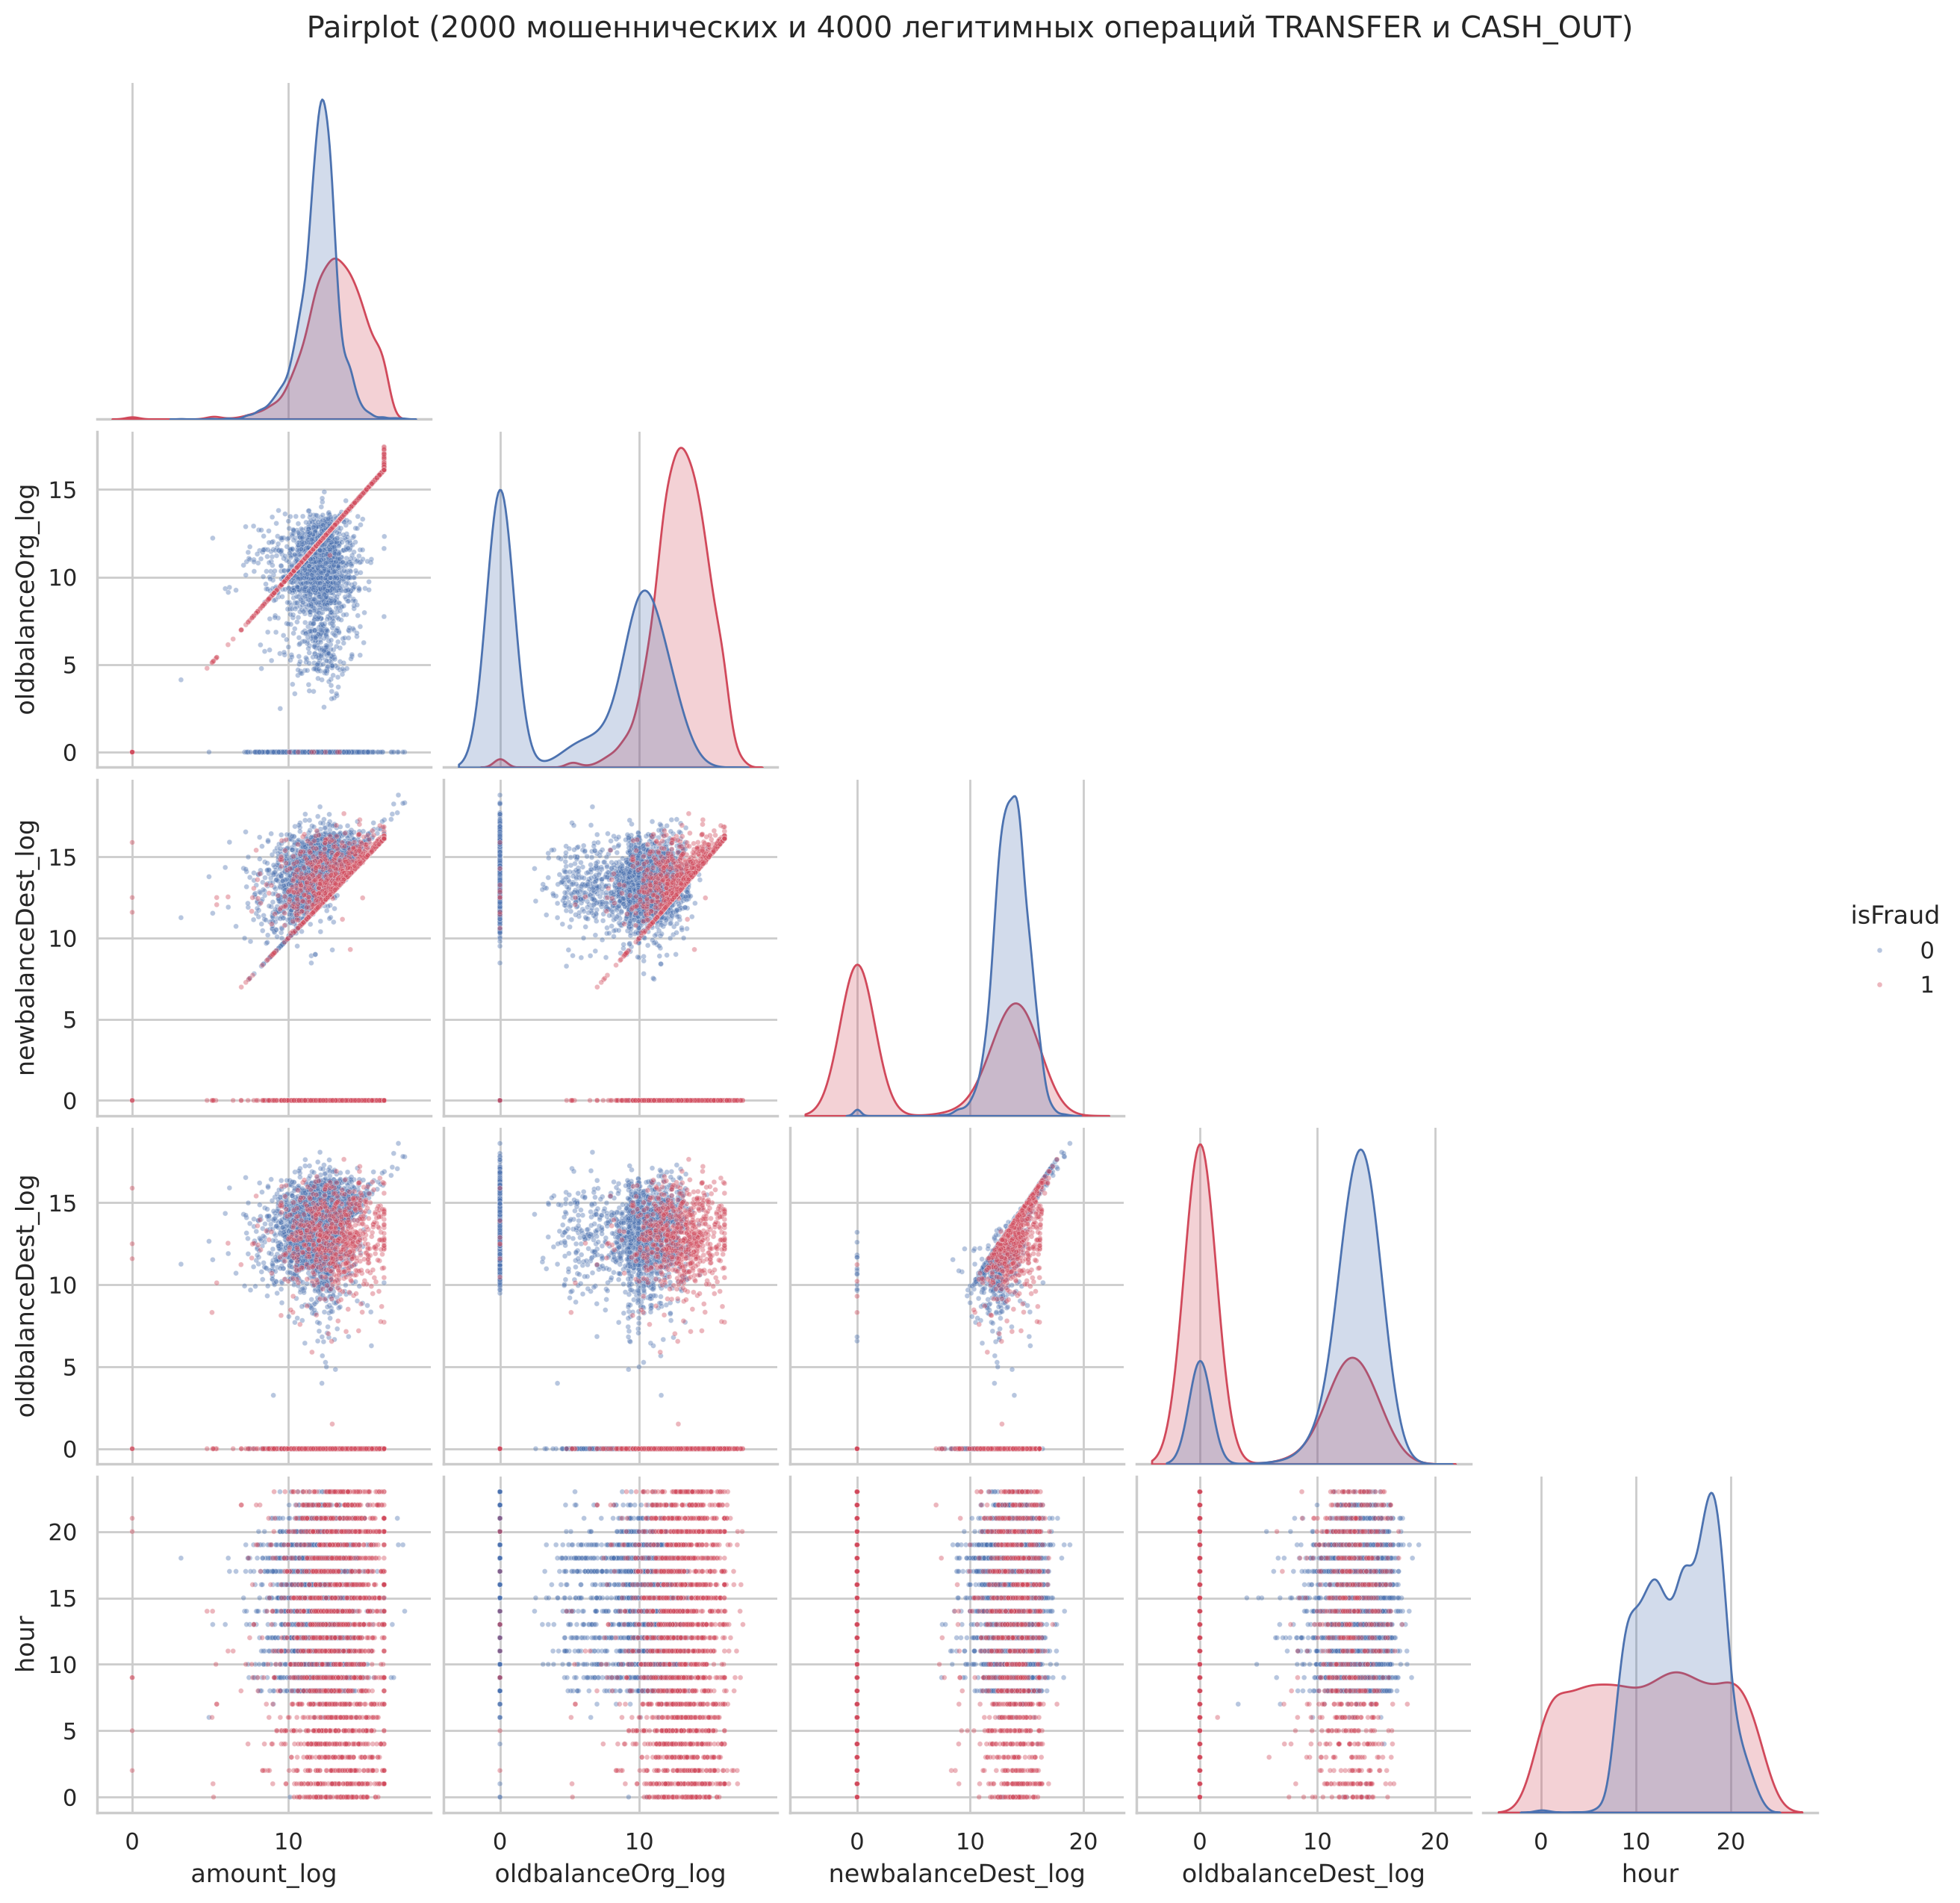

In [27]:
pp_cols = ['amount_log', 'oldbalanceOrg_log', 'newbalanceDest_log', 'oldbalanceDest_log', 'hour']
pp = pd.concat([t[~pos].sample(4000, random_state=RS), t[pos].sample(2000, random_state=RS)])[pp_cols + ['isFraud']]
g = sns.pairplot(pp, hue='isFraud', palette=PAL, plot_kws={'s': 6, 'alpha': 0.4}, diag_kws={'common_norm': False}, corner=True)
g.fig.suptitle('Pairplot (2000 мошеннических и 4000 легитимных операций TRANSFER и CASH_OUT)', y=1.02)
plt.show()

На графике `amount_log` против `oldbalanceOrg_log` мошенничество лежит ровно на диагонали (сумма равна балансу), а нормальные операции разбросаны вокруг нее и вдоль оси нулевого баланса. Это самая четкая граница в датасете, но задана она правилом генератора. На графиках с балансами получателя видно много мошенничества в нуле, это скрытые пропуски из раздела 3. По часу суток отделяются ночные мошеннические операции.

## 9. Сводные таблицы

In [28]:
t['amount_bin'] = pd.cut(t['amount'], [-1, 1e4, 1e5, 5e5, 1e6, 5e6, np.inf],
                         labels=['<10k', '10k-100k', '100k-500k', '500k-1M', '1M-5M', '>5M'])
t['day_part'] = pd.cut(t['hour'], [-1, 7, 11, 17, 23], labels=['ночь 0-7', 'утро 8-11', 'день 12-17', 'вечер 18-23'])
pv = pd.pivot_table(t, index='amount_bin', columns='type', values='isFraud', aggfunc='mean', observed=True) * 100
pv_n = pd.pivot_table(t, index='amount_bin', columns='type', values='isFraud', aggfunc='size', observed=True)
pd.concat({'fraud_rate_%': pv.round(3), 'n': pv_n}, axis=1)

fraud_rate_%                 n         
type           CASH_OUT TRANSFER CASH_OUT TRANSFER
amount_bin                                        
<10k             0.2020   2.1530    72761     6084
10k-100k         0.1020   1.2710   701308    55959
100k-500k        0.0940   0.6270  1410198   209798
500k-1M          1.1220   0.4380    51585   132209
1M-5M           76.3100   0.8380     1279   117713
>5M            100.0000   3.3640      369    11146

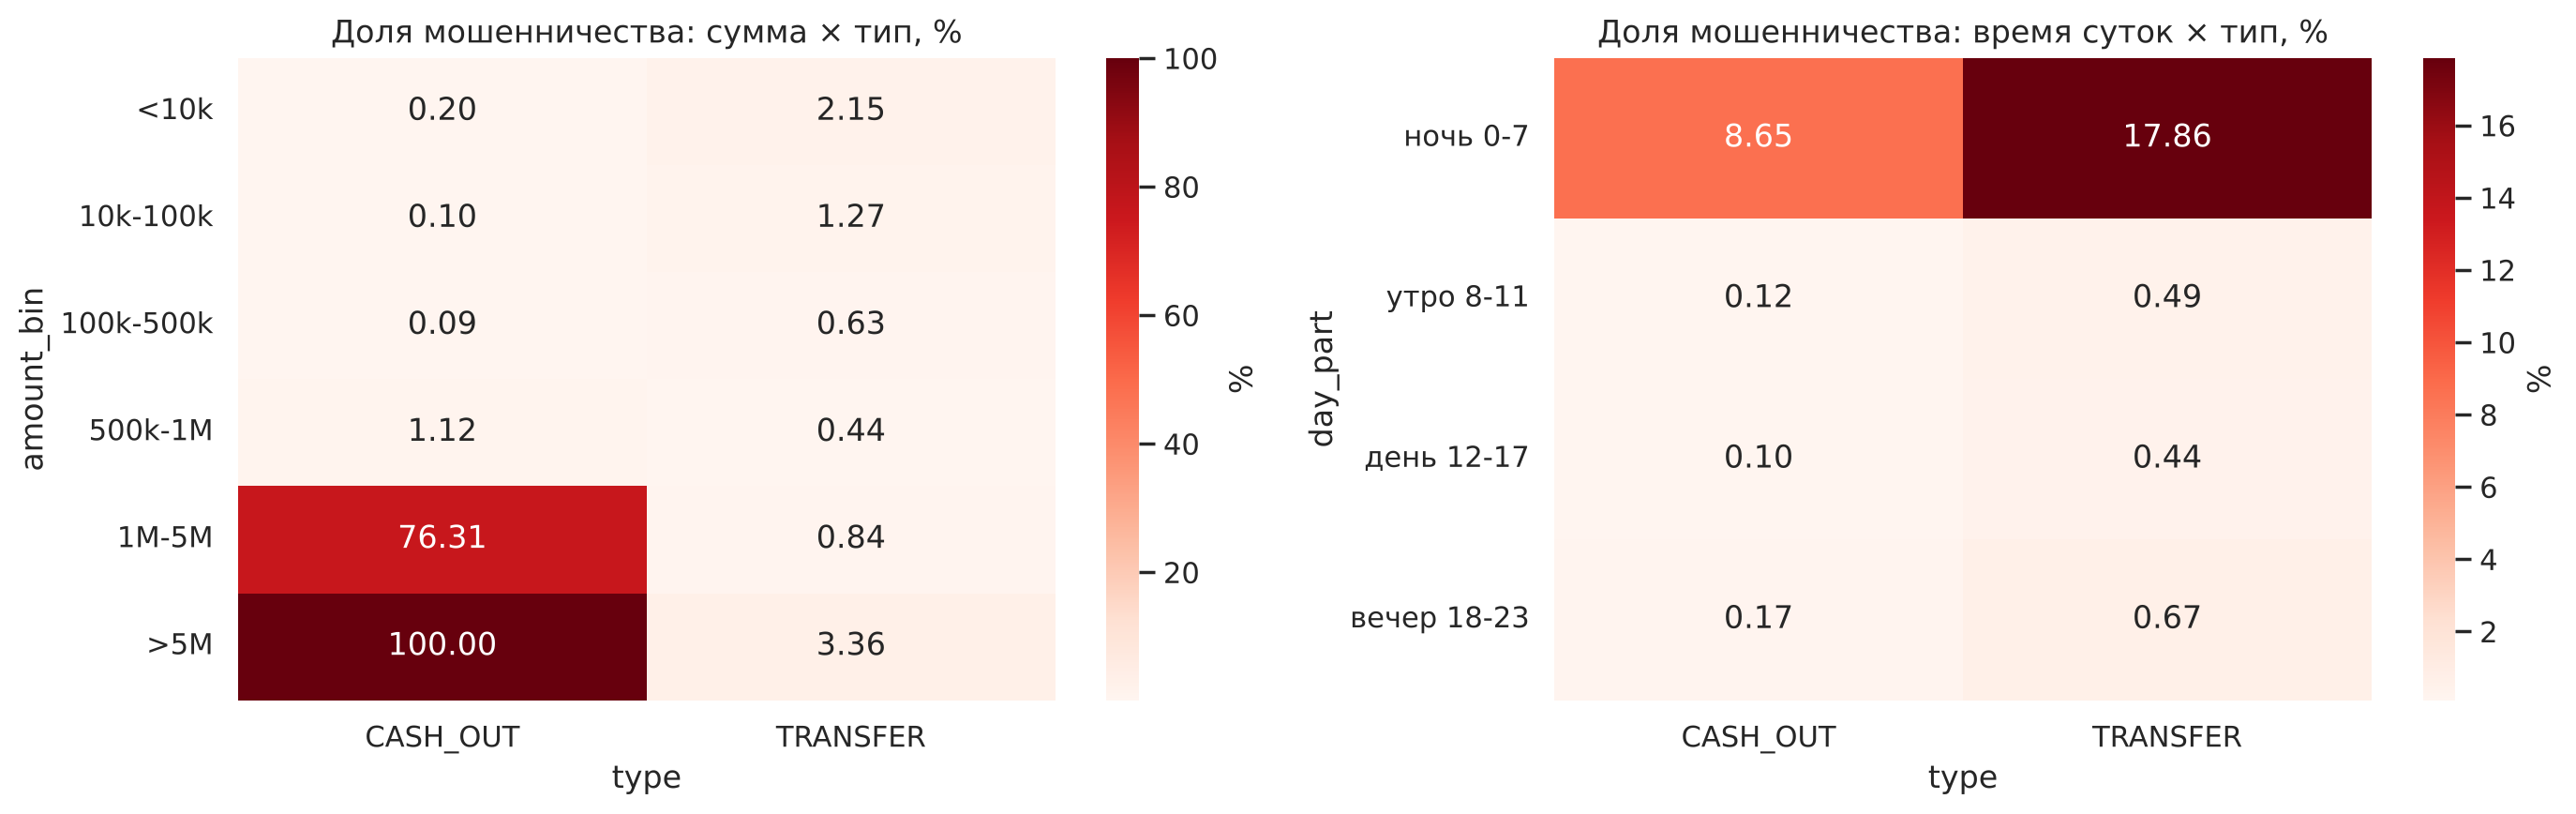

In [29]:
pv2 = pd.pivot_table(t, index='day_part', columns='type', values='isFraud', aggfunc='mean', observed=True) * 100
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(pv.round(2), annot=True, fmt='.2f', cmap='Reds', ax=axes[0], cbar_kws={'label': '%'})
axes[0].set_title('Доля мошенничества: сумма × тип, %')
sns.heatmap(pv2.round(2), annot=True, fmt='.2f', cmap='Reds', ax=axes[1], cbar_kws={'label': '%'})
axes[1].set_title('Доля мошенничества: время суток × тип, %')
plt.tight_layout()
plt.show()

In [30]:
t.groupby(['orig_bal_missing', 'dest_bal_missing', 'empties_account'])['isFraud'].agg(n='size', n_fraud='sum', fraud_rate='mean').round(4)

n  n_fraud  fraud_rate
orig_bal_missing dest_bal_missing empties_account                              
False            False            0                1451979        6      0.0000
                                  1                   4112     4112      1.0000
                 True             0                   1830      148      0.0809
                                  1                   3922     3922      1.0000
True             False            0                1308542       25      0.0000
                 True             0                     24        0      0.0000

- Зависимость от суммы разная для разных типов. В CASH_OUT мошенничества мало до 500 тыс., а среди операций больше 1 млн мошенничество составляет 76–100%. В TRANSFER зависимость U-образная, больше мошенничества на маленьких и на самых крупных суммах. Значит, модель должна учитывать взаимодействие типа и суммы.
- С 0 до 7 часов мошенничество составляет 9% в CASH_OUT и 18% в TRANSFER, а в остальное время 0.1–0.7%. В этом окне даже простая модель будет иметь высокий precision.
- Если счет опустошен полностью и баланс отправителя известен, то это почти всегда мошенничество. Это та же граница, что и на pairplot.

## 10. Типы аномальных наблюдений

In [31]:
anom_cols = ['amount_log', 'oldbalanceOrg_log', 'newbalanceOrig_log', 'oldbalanceDest_log', 'newbalanceDest_log', 'is_transfer']
X = t[anom_cols].to_numpy()
iso = IsolationForest(n_estimators=100, max_samples=4096, random_state=RS, n_jobs=-1).fit(X)
t['iso_score'] = -iso.score_samples(X)
print('Isolation Forest без меток, ROC-AUC:', round(roc_auc_score(t['isFraud'], t['iso_score']), 4))
print('Isolation Forest без меток, PR-AUC:', round(average_precision_score(t['isFraud'], t['iso_score']), 4))
thr = t['iso_score'].quantile(0.99)
tab = pd.crosstab(t['iso_score'] >= thr, t['isFraud'], margins=True)
tab.index = ['обычные (99%)', 'аномальные (top 1%)', 'всего']
tab

Isolation Forest без меток, ROC-AUC: 0.9013


Isolation Forest без меток, PR-AUC: 0.3028


isFraud,0,1,All
обычные (99%),2739208,3496,2742704
аномальные (top 1%),22988,4717,27705
всего,2762196,8213,2770409


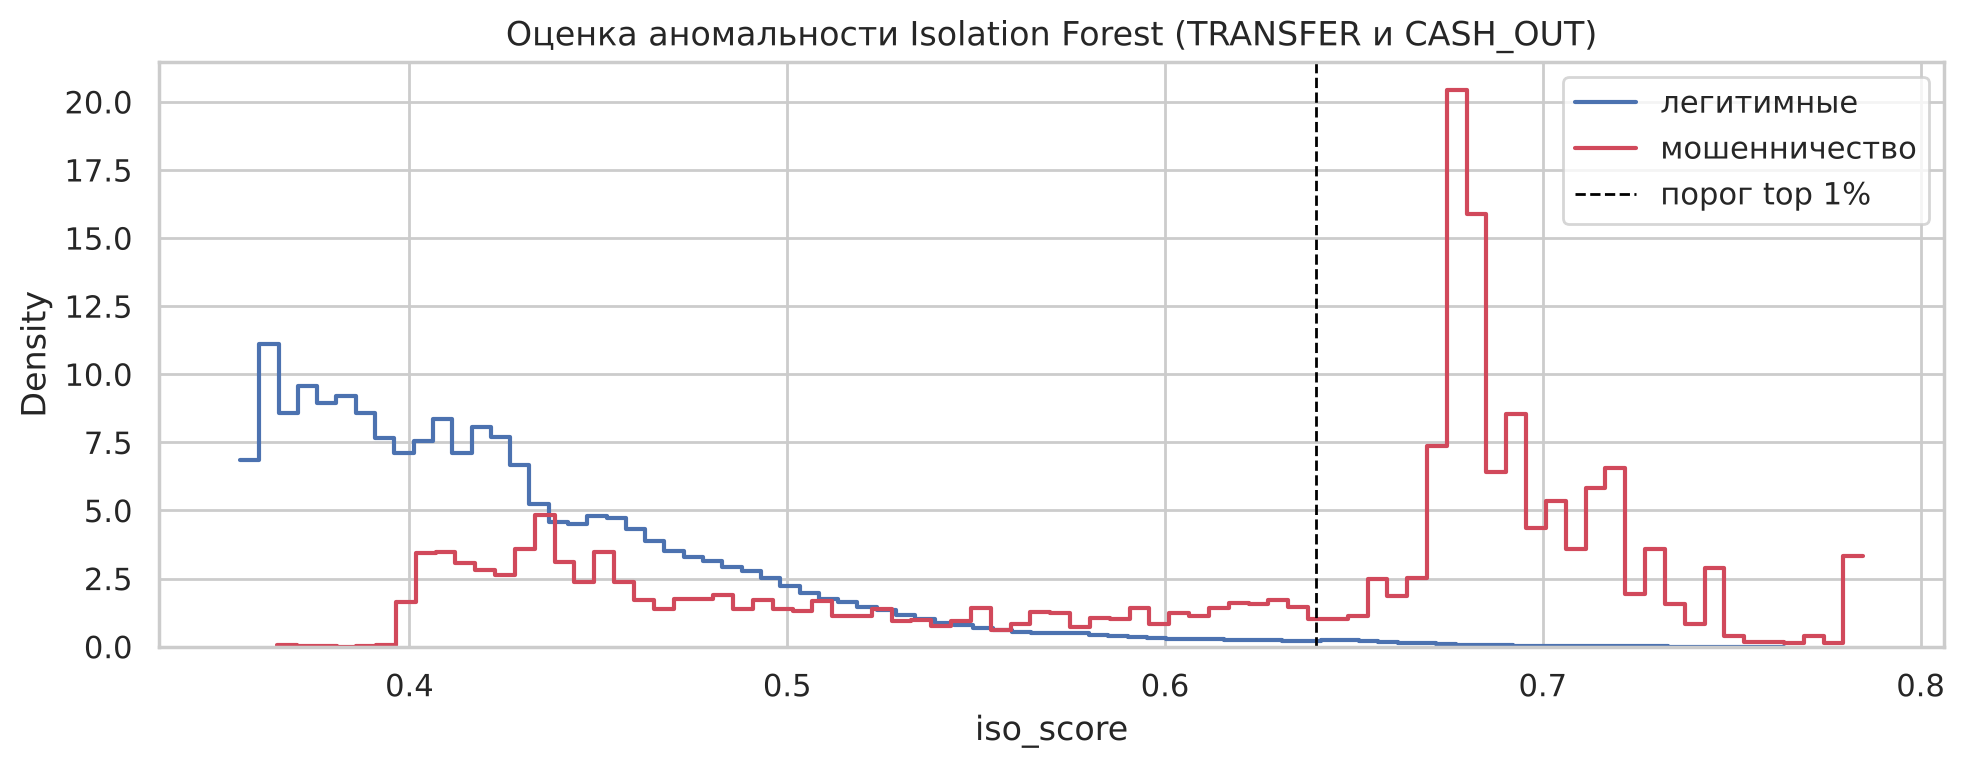

In [32]:
fig, ax = plt.subplots(figsize=(10, 4))
for cls in [0, 1]:
    sns.histplot(t.loc[t['isFraud'] == cls, 'iso_score'], bins=80, stat='density', element='step', fill=False,
                 color=PAL[cls], ax=ax, label=['легитимные', 'мошенничество'][cls])
ax.axvline(thr, color='black', ls='--', lw=1, label='порог top 1%')
ax.legend()
ax.set_title('Оценка аномальности Isolation Forest (TRANSFER и CASH_OUT)')
plt.tight_layout()
plt.show()

Isolation Forest без меток дает ROC-AUC около 0.90 и PR-AUC около 0.30, это в 100 раз лучше случайной модели, и в top 1% аномалий попадает 57% мошенничества. Но precision в этом top 1% всего 17%, то есть на одну пойманную мошенническую операцию приходится пять ложных срабатываний. Какие типы наблюдений тут видно:
- мошенничество как глобальная аномалия: крупные суммы, опустошенные счета с большим балансом, нулевые балансы получателя. Во многом это те же артефакты генератора, что и в разделах 3 и 4
- контекстные аномалии: оставшиеся 43% мошенничества выглядят как обычные переводы средних сумм и отличаются не самими значениями, а соотношением между ними (сумма равна балансу, ночное время)
- коллективные аномалии: у 99.5% мошеннических TRANSFER в том же часу есть CASH_OUT ровно на ту же сумму (проверка в следующей ячейке). Но id счетов в этих парах не совпадают, так что граф переводов по этому датасету не построить
- нормальные операции, похожие на аномалии: очень крупные переводы (до 92 млн) и странные сочетания балансов, это 83% top 1%. Отсюда и ложные срабатывания

Получается, что методы без учителя здесь работают заметно лучше случайного, но при высоком precision проиграют модели с учителем. Сравнивать их с XGBoost надо на одинаковых наборах признаков, в том числе на "реалистичном" (см. ниже).

In [33]:
ft = f[f['type'] == 'TRANSFER'][['step', 'amount', 'nameDest']]
fc = f[f['type'] == 'CASH_OUT'][['step', 'amount', 'nameOrig']]
pairs = ft.merge(fc, on=['step', 'amount'])
print('Мошеннических TRANSFER:', len(ft))
print('Из них имеют CASH_OUT на ту же сумму в том же шаге:', ft.set_index(['step', 'amount']).index.isin(fc.set_index(['step', 'amount']).index).mean().round(3))
print('Совпадает получатель TRANSFER и отправитель CASH_OUT:', (pairs['nameDest'] == pairs['nameOrig']).mean())

Мошеннических TRANSFER: 4097
Из них имеют CASH_OUT на ту же сумму в том же шаге: 0.995
Совпадает получатель TRANSFER и отправитель CASH_OUT: 0.0


## 11. Временная структура и потенциальные утечки

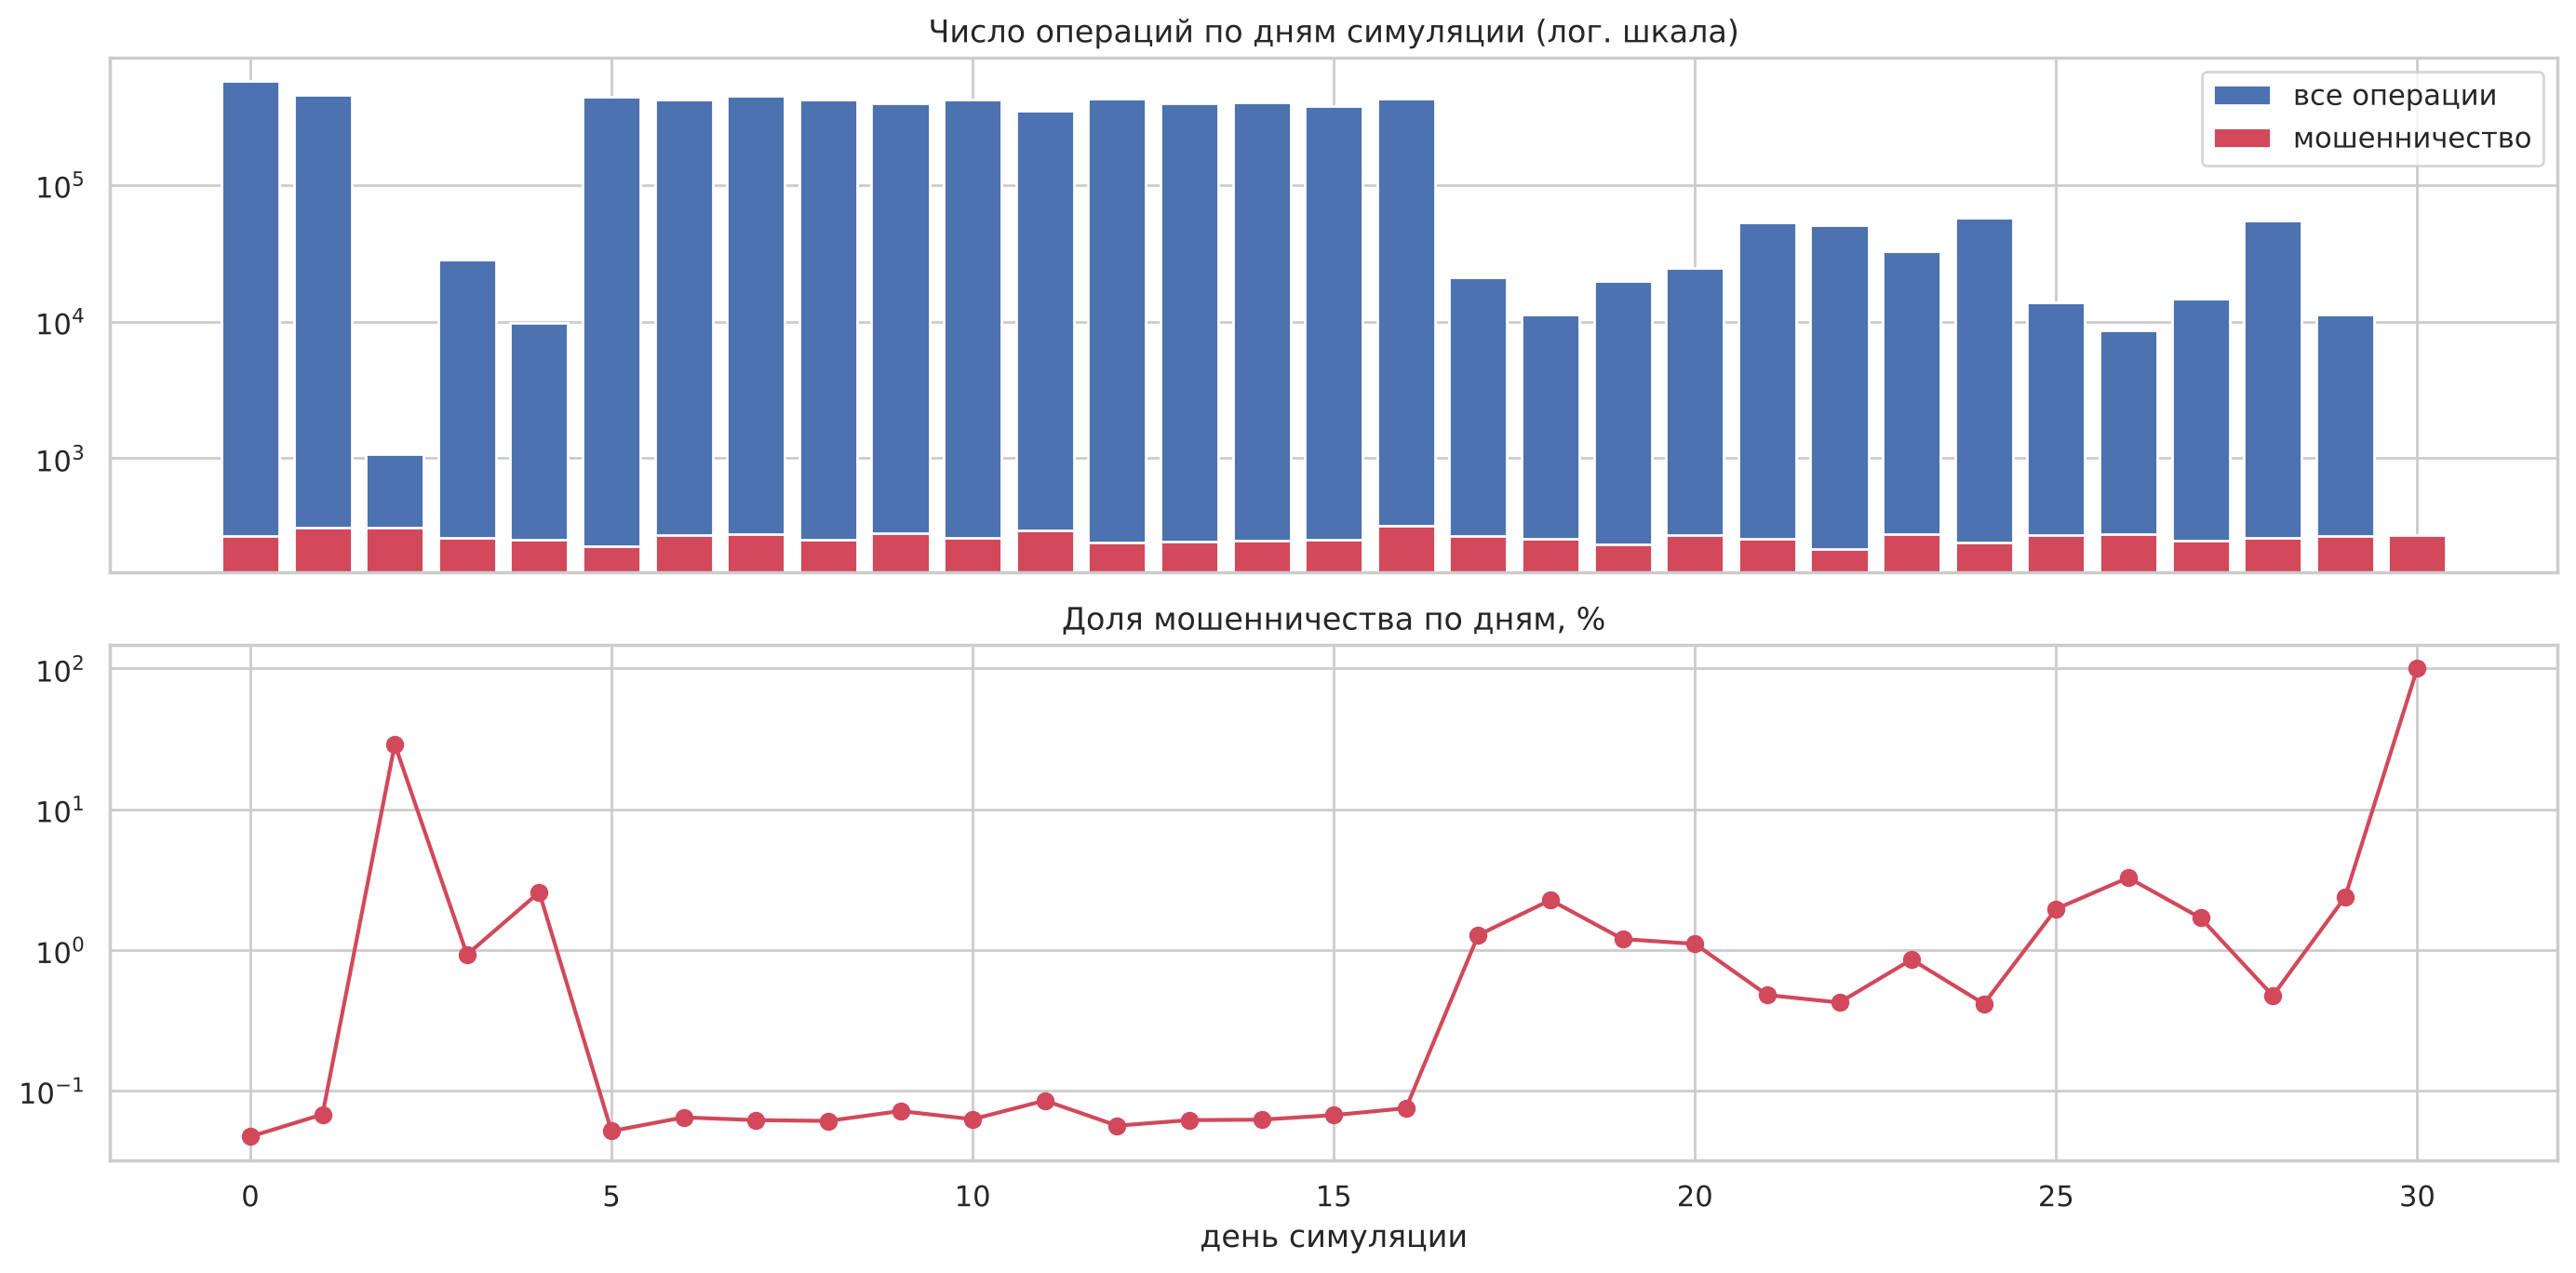

day,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
n,"574,255.0000","455,238.0000","1,070.0000","28,240.0000","9,789.0000","441,005.0000","420,583.0000","449,637.0000","417,919.0000","392,945.0000","417,859.0000","349,776.0000","428,583.0000","397,876.0000","401,282.0000","375,594.0000","425,766.0000","20,999.0000","11,300.0000","19,727.0000","24,593.0000","53,437.0000","51,012.0000","32,709.0000","57,853.0000","13,885.0000","8,578.0000","14,661.0000","54,890.0000","11,287.0000",272.0000
n_fraud,271.0000,309.0000,310.0000,262.0000,252.0000,228.0000,272.0000,278.0000,255.0000,282.0000,262.0000,298.0000,242.0000,246.0000,250.0000,252.0000,320.0000,268.0000,256.0000,236.0000,272.0000,256.0000,216.0000,280.0000,240.0000,272.0000,280.0000,248.0000,260.0000,268.0000,272.0000
fraud_rate,0.0005,0.0007,0.2897,0.0093,0.0257,0.0005,0.0006,0.0006,0.0006,0.0007,0.0006,0.0009,0.0006,0.0006,0.0006,0.0007,0.0008,0.0128,0.0227,0.0120,0.0111,0.0048,0.0042,0.0086,0.0041,0.0196,0.0326,0.0169,0.0047,0.0237,1.0000


In [34]:
dd = df.assign(day=(df['step'] - 1) // 24).groupby('day')['isFraud'].agg(n='size', n_fraud='sum', fraud_rate='mean')
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].bar(dd.index, dd['n'], color=PAL[0], label='все операции')
axes[0].bar(dd.index, dd['n_fraud'], color=PAL[1], label='мошенничество')
axes[0].set_yscale('log')
axes[0].set_title('Число операций по дням симуляции (лог. шкала)')
axes[0].legend()
axes[1].plot(dd.index, dd['fraud_rate'] * 100, marker='o', color=PAL[1])
axes[1].set_yscale('log')
axes[1].set_title('Доля мошенничества по дням, %')
axes[1].set_xlabel('день симуляции')
plt.tight_layout()
plt.show()
dd.T

Это, наверное, самая важная особенность датасета. Мошенничество генерируется почти постоянным потоком, примерно 250–300 операций в сутки, а количество нормальных операций сильно проседает на 3–5 день и после 17-го дня. Из-за этого доля мошенничества по дням меняется от 0.05% до десятков процентов, а в последний день вообще все операции мошеннические.

Что из этого следует:
- `step` и любые признаки абсолютного времени это утечка через артефакт симулятора, модель выучит "поздние дни значит мошенничество"
- precision и PR-AUC при временном разбиении будут зависеть от того, какие дни попали в тест, а не только от модели
- зато на этом датасете удобно проверять устойчивость к изменению доли мошенничества, что как раз есть в задачах проекта

Где может быть утечка:
- `isFlaggedFraud` это выход антифрод-системы, а не свойство операции. Удаляем.
- `step` и номер дня: доля мошенничества по дням определяется симулятором. Оставляем только `hour`.
- `newbalanceOrig`, `newbalanceDest` это состояние после операции, и для мошенничества симулятор заполняет их по особым правилам. Сравниваем модели с ними и без них.
- `err_orig`, `empties_account`, нулевые балансы получателя это артефакты генератора (сумма равна всему балансу, ограничение 10 млн). Считаем их "оптимистичным" набором признаков и отдельно смотрим модель без них.
- Частоты `nameDest` или target encoding получателя, посчитанные по всему датасету, используют будущее. Считаем только по прошлым шагам и out-of-fold.
- Случайное разбиение смешивает дни с совершенно разной долей мошенничества. Разбиваем по времени.

Проверим, насколько признаки с балансами "слишком хорошие". Обучим неглубокое дерево (глубина 3) на первых днях и проверим на следующих, с тремя наборами признаков.

In [35]:
cut = t['step'].quantile(0.7)
tr, te = t[t['step'] <= cut], t[t['step'] > cut]
sets = {
    'тип, сумма, час': ['is_transfer', 'amount_log', 'hour'],
    '+ балансы до операции': ['is_transfer', 'amount_log', 'hour', 'oldbalanceOrg_log', 'oldbalanceDest_log'],
    '+ балансы после и ошибки балансов': ['is_transfer', 'amount_log', 'hour', 'oldbalanceOrg_log', 'oldbalanceDest_log',
                                          'newbalanceOrig_log', 'newbalanceDest_log', 'err_orig', 'err_dest'],
}
res = {}
for name, cols in sets.items():
    m = DecisionTreeClassifier(max_depth=3, class_weight='balanced', random_state=RS).fit(tr[cols], tr['isFraud'])
    p = m.predict_proba(te[cols])[:, 1]
    res[name] = {'pr_auc_test': average_precision_score(te['isFraud'], p), 'roc_auc_test': roc_auc_score(te['isFraud'], p)}
print('Доля мошенничества в train:', round(tr['isFraud'].mean(), 5), 'в test:', round(te['isFraud'].mean(), 5))
pd.DataFrame(res).T.round(3)

Доля мошенничества в train: 0.00187 в test: 0.00558


,pr_auc_test,roc_auc_test
"тип, сумма, час",0.2060,0.8440
+ балансы до операции,0.0860,0.9440
+ балансы после и ошибки балансов,1.0000,1.0000


Дерево глубины 3, по сути несколько if-ов, на признаках с балансами после операции и ошибками балансов получает на будущих днях PR-AUC 1.0. Для реального антифрода так не бывает. На "реалистичном" наборе качество гораздо скромнее (у такого дерева мало разных значений скора, поэтому PR-AUC грубая, но разница все равно огромная).

Поэтому в проекте на PaySim будем показывать результаты для двух наборов признаков: "реалистичного" (тип, сумма, время, балансы до операции, без точного `empties_account` и без балансов после) и "полного". Вывод всего баланса и в реальности выглядит подозрительно, но в симуляторе нормальные клиенты так не делают никогда, поэтому точное равенство суммы и баланса превращается просто в метку класса.

## 12. Схема разбиения данных

In [36]:
s = t.sort_values('step')
q = s['step'].quantile([0.6, 0.8]).to_numpy()
s['split'] = np.select([s['step'] <= q[0], s['step'] <= q[1]], ['train', 'valid'], 'test')
s.groupby('split', sort=False).agg(n=('isFraud', 'size'), n_fraud=('isFraud', 'sum'), fraud_rate=('isFraud', 'mean'),
                                   step_from=('step', 'min'), step_to=('step', 'max')).round(5)

,n,n_fraud,fraud_rate,step_from,step_to
split,,,,,
train,1672907,3193,0.0019,1,281
valid,544998,762,0.0014,282,354
test,552504,4258,0.0077,355,743


Если разбить по `step`, объем частей нормальный, но доля мошенничества в тесте (0.77%) в 4 раза выше, чем в train (0.19%), потому что в тест попадают дни, когда нормальных операций почти нет. Поэтому для PaySim делаем так:
- оставляем только TRANSFER и CASH_OUT, в остальных типах мошенничества нет
- основное разбиение по времени (`step`), 60 / 20 / 20 на train / validation / test, без перемешивания
- дополнительно оцениваем модели на тесте, где доля мошенничества приведена к фиксированной (например, 0.1% и 0.3%), чтобы precision и PR-AUC можно было сравнивать между днями и с другими датасетами
- `step` в признаки не берем, `hour` берем, агрегаты по получателю считаем только по прошлым шагам

## 13. Выводы

1. 6.36 млн синтетических операций за 31 день, явных пропусков и дубликатов нет. Мошенничества 0.13% (1 к 774), и оно бывает только в TRANSFER и CASH_OUT (там 0.3%). Для модели оставляем 2.77 млн операций этих двух типов.
2. Нулевые балансы на самом деле пропуски. У мерчантов по построению (34% строк), а у клиентов-получателей и отправителей пропуски сильно зависят от таргета, то есть это не MCAR. Заменяем нули на NaN и добавляем индикаторы пропуска.
3. Балансы не сходятся у большинства операций, суммы часто больше баланса, есть 16 операций с нулевой суммой, а `isFlaggedFraud` работает не так, как написано в описании. Это особенности генератора, а не опечатки. Балансы не исправляем, `isFlaggedFraud` удаляем.
4. Суммы и балансы сильно скошены, `log1p` обязателен. Выбросы чаще мошеннические, поэтому их не удаляем. Нашли артефакт: мошенническая сумма не больше 10 млн, а крупные кражи разбиваются на куски по 10 млн.
5. Один признак "сумма равна всему балансу" дает PR-AUC 0.98, это правило генератора и почти прямая утечка. Из правдоподобных признаков сильные время суток (в 2–5 часов мошенничества 40–58%), тип операции и сумма, но связь с таргетом у них нелинейная и видна во взаимодействиях (тип и сумма, тип и время).
6. Isolation Forest без меток находит 57% мошенничества в top 1%, но precision там около 17%, большинство аномалий это крупные нормальные переводы. Примерно 43% мошенничества это контекстные аномалии, по отдельным значениям их не видно. Есть и коллективная структура (TRANSFER, потом CASH_OUT на ту же сумму в том же часу), но id счетов не связаны.
7. Число нормальных операций по дням сильно меняется, а мошенничество идет ровно, поэтому доля мошенничества по дням от 0.05% до 100%. Из-за этого `step` это утечка. Балансы после операции и признаки из них дают нереально хорошее качество даже для дерева глубины 3.
8. Разбиваем по времени 60 / 20 / 20 по `step` на TRANSFER и CASH_OUT, отдельно оцениваем на тесте с фиксированной долей класса и используем два набора признаков: реалистичный (без балансов после операции и без точного `empties_account`) и полный.

Что дальше: на PaySim в основном будем изучать устойчивость к изменению доли мошенничества и показывать, как утечки завышают метрики. Признаки тут понятные, так что SHAP будет осмысленным, и по нему можно будет проверить, не опирается ли модель на артефакты генератора.